In [1]:
import sys
sys.path.append('/cellar/users/atc009/DRPT-MAML/new_MAML_model') 

In [2]:
import pandas as pd
import torch
import numpy as np
import argparse
from torch.utils.data.dataloader import DataLoader

import torch
import torchtuples as tt
import torch.nn.parallel
import torch.distributed as dist
import torch.optim as optim
import torch.multiprocessing as mp
import torch.utils.data
import torch.utils.data.distributed

from pycox.models import CoxTime
from pycox.models.cox_time import MLPVanillaCoxTime

from survival_dataloader import SimpleSurvivalMetaDataset, SimpleSurvivalCollator, SimpleSurvivalTaskSampler
from survival_MAML_trainer import SurvivalMAMLTrainer, SurvivalMLP

from sklearn.model_selection import StratifiedShuffleSplit, ShuffleSplit

In [3]:
# Check distribution of classes in METABRIC dataset
# Filter out noise (samples that have not reached full duration of dosing-- event or censored at <= 2 months)
metabric_expr_mut = pd.read_csv('/cellar/users/atc009/ARPA_ADAPT_data/METABRIC_RNA_Mutation.csv')
print("Total number of patients, unfiltered: ", len(metabric_expr_mut))
metabric_expr_mut = metabric_expr_mut[metabric_expr_mut['overall_survival_months'] > 2.]
print("Total number of patients, filtered for > 2mo OS: ", len(metabric_expr_mut))
metabric_expr_mut.head()

Total number of patients, unfiltered:  1904
Total number of patients, filtered for > 2mo OS:  1896


/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3457: DtypeWarning: Columns (678,688,690,692) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,...,mtap_mut,ppp2cb_mut,smarcd1_mut,nras_mut,ndfip1_mut,hras_mut,prps2_mut,smarcb1_mut,stmn2_mut,siah1_mut
0,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
1,2,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
2,5,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
3,6,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
4,8,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0


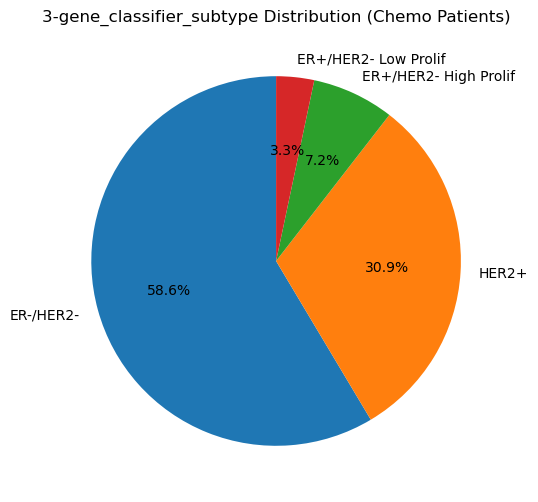

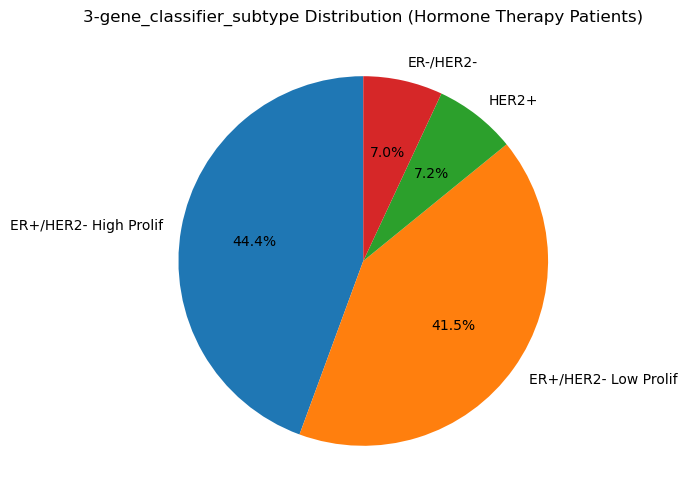

In [4]:
chemo_only = metabric_expr_mut[(metabric_expr_mut['chemotherapy'] == 1) & (metabric_expr_mut['hormone_therapy'] == 0)]
ht_only = metabric_expr_mut[(metabric_expr_mut['chemotherapy'] == 0) & (metabric_expr_mut['hormone_therapy'] == 1)]

import matplotlib.pyplot as plt

# Pie chart for chemo patients
chemo_counts = chemo_only['3-gene_classifier_subtype'].value_counts()
plt.figure(figsize=(6, 6))
chemo_counts.plot.pie(autopct='%1.1f%%', startangle=90)
plt.title('3-gene_classifier_subtype Distribution (Chemo Patients)')
plt.ylabel('')
plt.show()

# Pie chart for hormone therapy patients
ht_counts = ht_only['3-gene_classifier_subtype'].value_counts()
plt.figure(figsize=(6, 6))
ht_counts.plot.pie(autopct='%1.1f%%', startangle=90)
plt.title('3-gene_classifier_subtype Distribution (Hormone Therapy Patients)')
plt.ylabel('')
plt.show()

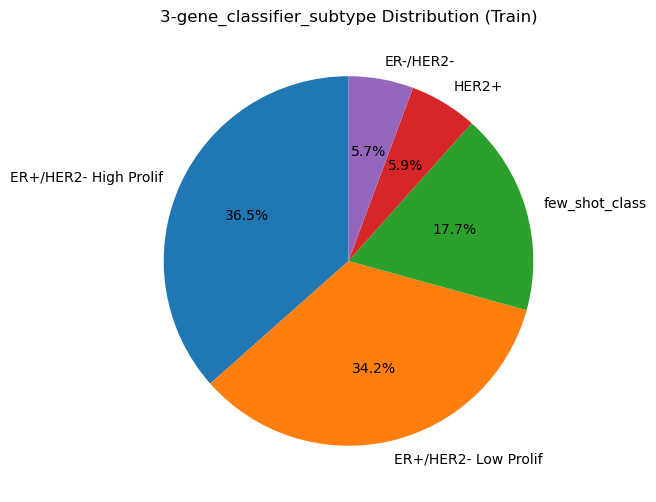

In [102]:
# Pie chart for pretraining and test data
train_response = pd.read_csv('/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_metabric_train_response.csv', index_col=0)
target_response = pd.read_csv('/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_metabric_target_response.csv', index_col=0)

# few_shot_ind = train_response[train_response['class'] == 'few_shot_class'].index
# pretrain_response = train_response.drop(few_shot_ind)
# few_shot_response = train_response.iloc[few_shot_ind]

train_counts = train_response['class'].value_counts()
plt.figure(figsize=(6, 6))
train_counts.plot.pie(autopct='%1.1f%%', startangle=90)
plt.title('3-gene_classifier_subtype Distribution (Train)')
plt.ylabel('')
plt.show()

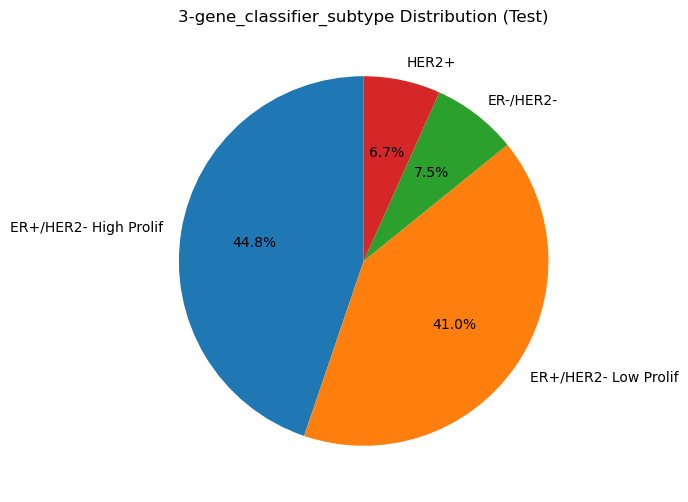

In [103]:
target_counts = target_response['class'].value_counts()
plt.figure(figsize=(6, 6))
target_counts.plot.pie(autopct='%1.1f%%', startangle=90)
plt.title('3-gene_classifier_subtype Distribution (Test)')
plt.ylabel('')
plt.show()

In [5]:
# Drop samples with missing biomarker class
metabric_expr_mut = metabric_expr_mut.dropna(subset=['3-gene_classifier_subtype'])

In [6]:
# Patient counts for chemo, HT, both, neither
chemo_only = metabric_expr_mut[(metabric_expr_mut['chemotherapy'] == 1) & (metabric_expr_mut['hormone_therapy'] == 0)]
ht_only = metabric_expr_mut[(metabric_expr_mut['chemotherapy'] == 0) & (metabric_expr_mut['hormone_therapy'] == 1)]
both = metabric_expr_mut[(metabric_expr_mut['chemotherapy'] == 1) & (metabric_expr_mut['hormone_therapy'] == 1)]
neither = metabric_expr_mut[(metabric_expr_mut['chemotherapy'] == 0) & (metabric_expr_mut['hormone_therapy'] == 0)]

labels = ['Chemo Only', 'HT Only', 'Both', 'Neither']
sizes = [len(chemo_only), len(ht_only), len(both), len(neither)] 
print(sizes)

[181, 892, 166, 453]


## Collect features

In [86]:
# Separate datset into patient2ind, drug response, expression, and mutation data
# Target/Val: chemo only
# Train: HT only + both

train_df = pd.concat([ht_only, both], ignore_index=True)
train_df['class'] = train_df['3-gene_classifier_subtype']
target_df = chemo_only
target_df['class'] = target_df['3-gene_classifier_subtype']

/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/site-packages/ipykernel_launcher.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


In [87]:
# train_patient2ind = {pid: i for i, pid in enumerate(train_df['patient_id'])}
# train_respose = train_df[['patient_id', '3-gene_classifier_subtype', 'overall_survival_months', 'overall_survival']]
# train_expression = train_df[train_df.columns[31:520]]
# train_mut = train_df.filter(regex='\w+_mut$')

# target_patient2ind = {pid: i for i, pid in enumerate(target_df['patient_id'])}
# target_respose = target_df[['patient_id', '3-gene_classifier_subtype', 'overall_survival_months', 'overall_survival']]
# target_expression = target_df[target_df.columns[31:520]]
# target_mut = target_df.filter(regex='\w+_mut$')

In [39]:
# Holdout target class for few-shot and validation split
target_class = 'HER2+'
train_ht_only = ht_only[ht_only['3-gene_classifier_subtype']!=target_class]
test_ht_only = ht_only[ht_only['3-gene_classifier_subtype']==target_class]

print('Samples in train: ', len(train_ht_only))
print('Samples in test: ', len(test_ht_only))

Samples in train:  828
Samples in test:  64


In [40]:
# TODO: Positive control-- should perform well
# Target/Val: HT only (pan-subtype)
# Train: HT only (between subtypes)

# First look at original distribution
print("Original distribution:")
print(ht_only['3-gene_classifier_subtype'].value_counts(normalize=True))

# sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
# for train_index, test_valid_index in sss1.split(ht_only, ht_only['3-gene_classifier_subtype']):
#     ht_train_set = ht_only.iloc[train_index]
#     ht_test_valid_set = ht_only.iloc[test_valid_index]

# sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
# for test_index, valid_index in sss2.split(ht_test_valid_set, ht_test_valid_set['3-gene_classifier_subtype']):
#     ht_test_set = ht_test_valid_set.iloc[test_index]
#     ht_valid_set = ht_test_valid_set.iloc[valid_index]

# Only split test set into few-shot and validation
ss1 = ShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
for test_index, valid_index in ss1.split(test_ht_only):
    ht_test_set = test_ht_only.iloc[test_index]
    ht_valid_set = test_ht_only.iloc[valid_index]
    
# Verify distributions
# print("\nTrain distribution:")
# print(ht_train_set['3-gene_classifier_subtype'].value_counts(normalize=True))

# print("\nTest distribution:")
# print(ht_test_set['3-gene_classifier_subtype'].value_counts(normalize=True))

# print("\nValid distribution:")
# print(ht_valid_set['3-gene_classifier_subtype'].value_counts(normalize=True))

print('Samples in train: ', len(train_ht_only))
print('Samples in few-shot: ', len(ht_test_set))
print('Samples in validation: ', len(ht_valid_set))

Original distribution:
ER+/HER2- High Prolif    0.443946
ER+/HER2- Low Prolif     0.414798
HER2+                    0.071749
ER-/HER2-                0.069507
Name: 3-gene_classifier_subtype, dtype: float64
Samples in train:  828
Samples in few-shot:  32
Samples in validation:  32


In [41]:
train_ht_only['class'] = train_ht_only['3-gene_classifier_subtype']
ht_test_set['class'] = ht_test_set['3-gene_classifier_subtype'] 

# Select for specific sub-type as target class, different from classes in train (validation is held out as separate dataset)
train_fewshot_df = pd.concat([train_ht_only, ht_test_set], ignore_index=True)

ht_valid_set['class'] = ht_valid_set['3-gene_classifier_subtype']
# target_train = target_train.reset_index(drop=True)
ht_valid_set = ht_valid_set.reset_index(drop=True)

/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.
/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/site-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  
/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/site-packages/ipykernel_launcher.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

In [42]:
target_val = ht_valid_set

In [43]:
# Concat part of target data for few-shot learning to train data, and leave rest as validation 

# # First look at original distribution
# print("Original distribution:")
# print(target_df['3-gene_classifier_subtype'].value_counts(normalize=True))

# # Create stratified split
# sss = StratifiedShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
# split = next(sss.split(target_df, target_df['3-gene_classifier_subtype']))

# target_train = target_df.iloc[split[0]]
# target_val = target_df.iloc[split[1]]

# # Verify distributions
# print("\nFirst half distribution:")
# print(target_train['3-gene_classifier_subtype'].value_counts(normalize=True))

# print("\nSecond half distribution:")
# print(target_val['3-gene_classifier_subtype'].value_counts(normalize=True))

# target_train['class'] = 'few_shot_class' # + target_train['class']
# train_fewshot_df = pd.concat([train_df, target_train], ignore_index=True)

# # target_train = target_train.reset_index(drop=True)
# target_val = target_val.reset_index(drop=True)

In [44]:
train_patient2ind = train_fewshot_df[['patient_id']]
train_response = train_fewshot_df[['patient_id', 'class', 'overall_survival_months', 'overall_survival']]
train_expression = train_fewshot_df[train_fewshot_df.columns[31:520]]
# train_expression = train_fewshot_df[['patient_id'] + list(train_fewshot_df.columns[31:520])]
train_mut = train_fewshot_df.filter(regex='\w+_mut$')
# train_mut = train_fewshot_df[['patient_id'] + list(train_fewshot_df.filter(regex='\w+_mut$').columns)]

# mask_cols = [col for col in train_mut.columns if col != 'patient_id']
train_mut = train_mut.replace({col: {'0': 0} for col in train_mut.columns})  # Ensure 0s are numeric
train_mut = train_mut.mask(train_mut != 0, 1)  # Replace non-zero values with 1
train_mut.columns = train_mut.columns.str.replace('_mut', '') # Remove '_mut' suffix from column names

In [45]:
target_patient2ind = target_val[['patient_id']]
target_response = target_val[['patient_id', 'class', 'overall_survival_months', 'overall_survival']]
target_expression = target_val[target_val.columns[31:520]]
# target_expression = target_val[['patient_id'] + list(target_val.columns[31:520])]
target_mut = target_val.filter(regex='\w+_mut$')
# target_mut = target_val[['patient_id'] + list(target_val.filter(regex='\w+_mut$').columns)]

# mask_cols = [col for col in target_mut.columns if col != 'patient_id']
target_mut = target_mut.replace({col: {'0': 0} for col in target_mut.columns})  # Ensure 0s are numeric
target_mut = target_mut.mask(target_mut != 0, 1)  # Replace non-zero values with 1
target_mut.columns = target_mut.columns.str.replace('_mut', '') # Remove '_mut' suffix from column names

In [46]:
# Store feature and response data
train_patient2ind.to_csv('/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_train_patient2ind.csv')
train_response.to_csv('/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_train_response.csv')
train_expression.to_csv('/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_train_expression.csv')
train_mut.to_csv('/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_train_mutation.csv')

target_patient2ind.to_csv('/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_target_patient2ind.csv')
target_response.to_csv('/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_target_response.csv')
target_expression.to_csv('/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_target_expression.csv')
target_mut.to_csv('/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_metabric_HER2+_fewshot_target_mutation.csv')


## Set up dataloaders and model training

In [33]:
# survival_dataloader.py
# Task sampler for survival data
class SimpleSurvivalMetaDataset:
    
    def __init__(self, drug_response_file, patient2ind_file, genotype_files, 
                 class_ind=1, time_col=2, event_col=3):
        """
        Args:
            drug_response_file: CSV with [patient_id, drug, time, event, ...]
            patient2ind_file: CSV mapping patient_id to index
            genotype_files: Dict {'mutation': 'path/to/mutations.txt', 'cna': 'path/to/cna.txt', 'expression': 'path/to/expression.txt'}
            class_ind: Column index for grouping (e.g., drug, cancer subtype, etc.)
            time_col: Column index for survival time
            event_col: Column index for event indicator
        """
        # Load drug response data
        self.drug_response = pd.read_csv(drug_response_file, index_col=0)
        self.drug_response['patient_id'] = self.drug_response['patient_id'].astype(str)
        self.class_ind = class_ind
        self.time_col = time_col
        self.event_col = event_col

        # TODO: Implement CoxTime model to instantiate CoxTimeDataset (loads case and control pairs)
        # self.labtrans = CoxTime.label_transform()
        # self.make_dataset = CoxTime

        # Get name for class grouping
        class_col_name = self.drug_response.columns[class_ind]
        
        # Get unique classes (drugs/treatments)
        self.classes = list(self.drug_response.iloc[:, class_ind].unique())
        self.drug_response_df_grouped = self.drug_response.groupby(by=class_col_name)
        
        # Load patient to index mapping
        patient2ind_df = pd.read_csv(patient2ind_file)
        self.patient2ind = {str(patient): idx for idx, patient in patient2ind_df.itertuples(False)}
        
        # Load genomic data files
        self.genotype_data = {}
        for genotype_type, file_path in genotype_files.items():
            if genotype_type in ['mutation', 'cna']:
                print("Loading mutation/CNA data...")
                self.genotype_data[genotype_type] = pd.read_csv(file_path, index_col=0).astype('int32')
            else:
                print("Loading expression...")
                self.genotype_data[genotype_type] = pd.read_csv(file_path, index_col=0).astype('float')
        
        # Subset for genes that have all genotype types
        # NOTE: Might not be necessary, but keeps consistency across types 
        # common_genes = set(self.genotype_data[next(iter(genotype_files))].columns)
        # for genotype_type in genotype_files.keys():
        #     self.genotype_data[genotype_type] = self.genotype_data[genotype_type][list(common_genes)]
        
        self.genotype_types = list(genotype_files.keys())

    def __len__(self):
        return self.drug_response.shape[0]

    def __getitem__(self, index):
        """Get a single sample with genomic features and survival data"""
        row = self.drug_response.iloc[index]
        # print("Row: ", row, "Index: ", index)
        
        # Extract basic information
        patient_id = str(row.iloc[0])
        class_type = row.iloc[self.class_ind]
        time = float(row.iloc[self.time_col])
        event = float(row.iloc[self.event_col])

        # DEBUG: patient_id type is str, but can't be found in patient2ind?
        # print("Row index: ", index)
        # print("Patient ID being passed in: ", patient_id)
        # print("Data type of patient ID: ", type(patient_id))

        # Get patient index
        if patient_id not in self.patient2ind:
            # print("patient_id type: ", type(patient_id))
            raise KeyError(f"patient_id {patient_id} not found in patient2ind")
        patient_ind = self.patient2ind.get(patient_id, 0)
        
        # Extract genomic features for this patient
        genotype_features = {}
        for genotype_type in self.genotype_types:
            # Get binary feature vector for this patient
            features = self.genotype_data[genotype_type].iloc[patient_ind].values
            genotype_features[genotype_type] = torch.tensor(features, dtype=torch.float32)
            # print("Genotype index sample:", self.genotype_data[genotype_type].index[:5].tolist())
        
        return {
            'patient_id': patient_id,
            'genotype': genotype_features,
            'class': class_type,
            'time': torch.tensor(time, dtype=torch.float32),
            'event': torch.tensor(event, dtype=torch.float32)
        }

class SimpleSurvivalCollator:
    """Simple collator that flattens genomic features"""
    
    def __init__(self, genotype_types):
        self.genotype_types = genotype_types
    
    def __call__(self, batch):
        """Convert batch of samples to MLP-friendly format"""
        if not batch:
            return {}
        
        # Collect survival data
        times = torch.stack([sample['time'] for sample in batch])
        events = torch.stack([sample['event'] for sample in batch])
        
        # Flatten and concatenate genomic features
        all_features = []
        for genotype_type in self.genotype_types:
            # Stack features for this genotype type across batch
            genotype_features = torch.stack([sample['genotype'][genotype_type] for sample in batch])
            all_features.append(genotype_features)
        
        # Concatenate all genomic feature types
        combined_features = torch.cat(all_features, dim=1) if all_features else torch.zeros(len(batch), 100)
        
        return {
            'features': combined_features,
            'time': times,
            'event': events,
            'classes': [sample['class'] for sample in batch],
            'patient_ids': [sample['patient_id'] for sample in batch]
        }

class SimpleSurvivalTaskSampler:
    """Simplified task sampler"""
    
    def __init__(self, dataset, collator, num_support, num_query, rank, world_size, test_class):
        self.dataset = dataset
        self.collator = collator
        # self.num_classes_per_task = num_classes_per_task
        self.num_support = num_support
        self.num_query = num_query
        self.rank = rank
        self.world_size = world_size
        self.test_class = test_class
        self.all_classes = list(set(self.dataset.classes) - {self.test_class})
        
        self._shuffle_classes()

    def _shuffle_classes(self):
        """Assign classes to this rank"""
        random.shuffle(self.all_classes)
        
        if self.world_size > 1:
            classes_per_rank = len(self.all_classes) // self.world_size
            start_idx = self.rank * classes_per_rank
            end_idx = start_idx + classes_per_rank
            self.assigned_classes = self.all_classes[start_idx:end_idx]
        else:
            self.assigned_classes = self.all_classes

    def get_n_class_samples(self, class_label, n_samples):
        """Get n samples from a specific class"""
        if class_label not in self.dataset.drug_response_df_grouped.groups:
            return []
        
        indices = self.dataset.drug_response_df_grouped.groups[class_label].tolist()
        
        if len(indices) < n_samples:
            print(f"Warning: Class {class_label} has only {len(indices)} samples, requested {n_samples}")
            return [self.dataset[i] for i in indices]
            

        # Random sample without replacement
        sampled_indices = random.sample(indices, n_samples)
        return [self.dataset[i] for i in sampled_indices]

    def sample_task(self):
        """Sample support and query sets"""
        available_classes = [cls for cls in self.assigned_classes 
                           if cls in self.dataset.drug_response_df_grouped.groups]
        
#         if len(available_classes) < self.num_classes_per_task:
#             selected_classes = available_classes
#         else:

        # NOTE: Choose one class that both support and query are from
        selected_class = random.choice(available_classes)

        # support_set = []
        # query_set = []

        # for class_label in selected_classes:
        total_needed = self.num_support + self.num_query
        class_samples = self.get_n_class_samples(selected_class, total_needed)
        
        # STRATIFIED SAMPLING - separate events and censored
        events = [s for s in class_samples if s['event'] == 1]
        censored = [s for s in class_samples if s['event'] == 0]
        
        print(f"Training data available for stratification: {len(events)} events, {len(censored)} censored")

        if len(class_samples) < total_needed:
            split_point = len(class_samples) // 2
            support_samples = class_samples[:split_point]
            query_samples = class_samples[split_point:]
        else:
            # support_samples = class_samples[:self.num_support]
            # query_samples = class_samples[self.num_support:total_needed]
            
            # NOTE: Ensure both support and query sets contain some events (to use Cox Time case-control pair generation)
            # Stratified split - ensure both sets get events
            n_support_events = max(1, len(events) // 2) if len(events) >= 2 else len(events)
            n_query_events = len(events) - n_support_events

            n_support_censored = self.num_support - n_support_events
            n_query_censored = self.num_query - n_query_events

            # Shuffle each group independently
            random.shuffle(events)
            random.shuffle(censored)

            # Combine stratified samples
            support_samples = events[:n_support_events] + censored[:n_support_censored]
            query_samples = events[n_support_events:] + censored[n_support_censored:n_support_censored + n_query_censored]

            # Shuffle the combined sets (so events aren't always first)
            random.shuffle(support_samples)
            random.shuffle(query_samples)

        # support_set.extend(support_samples)
        # query_set.extend(query_samples)

        # Convert to batches
        support = self.collator(support_samples) if support_samples else {}
        query = self.collator(query_samples) if query_samples else {}
        
        # Debug prints
        if support:
            n_support_events = (support.get('event', support.get('events', [])) == 1).sum()
            print(f"Support: {n_support_events} events / {len(support_samples)} total")
        if query:
            n_query_events = (query.get('event', query.get('events', [])) == 1).sum()
            print(f"Query: {n_query_events} events / {len(query_samples)} total")
        
        # print(f"Class types in support: {support['classes'].unique()}")
        # print(f"Class types in query: {query['classes'].unique()}")
        support_classes = set(support['classes'])
        query_classes = set(query['classes'])
        if len(support_classes) > 1 or len(query_classes) > 1:
            raise ValueError(f" Multiple classes in task! Support: {support_classes}, Query: {query_classes}")

        return support, query
    
# Make separate class for few-shot sampler (only from hold-out validation dataloader)
class SurvivalFewShotSampler:
    """Few-shot sampler"""
    
    def __init__(self, dataset, collator, k_shot, test_class):
        self.dataset = dataset
        self.collator = collator
        self.k_shot = k_shot
        # self.rank = rank
        # self.world_size = world_size
        self.test_class = test_class
        # self.all_classes = list(set(self.dataset.classes) - {self.test_class})

    def get_few_shot(self, seed):
        """Get few-shot data for specific class"""
        class_label = self.test_class  # Ensure we only get data for the test class
        n_samples = self.k_shot
        if class_label not in self.dataset.drug_response_df_grouped.groups:
            raise ValueError(f"Target class {class_label} not found in dataset")
            # return {}, {}
            
        indices = self.dataset.drug_response_df_grouped.groups[class_label].tolist()
        
#         if n_samples == 0:
#             # Return empty k_data and all test data (for zero-shot evaluation)
#             k_data = {}
#             test_data = self.collator([self.dataset[i] for i in indices])
        
        if len(indices) <= n_samples:
            print(f"Warning: Requested {n_samples} samples but target class only has {len(test_indices)}")
            k_indices = indices
            test_indices = []
        else:
            random.seed(seed)
            random.shuffle(indices)
            k_indices = indices[:n_samples]
            test_indices = indices[n_samples:]

            k_data = self.collator([self.dataset[i] for i in k_indices]) if k_indices else {}
            test_data = self.collator([self.dataset[i] for i in test_indices]) if test_indices else {}
        
        # print(f"Class types in few-shot: {k_data['classes'].unique()}")
        # print(f"Class types in test: {test_data['classes'].unique()}")
        
        return k_data, test_data
    
    def get_few_shot_stratified(self, seed, min_events=1):
        """
        Sample k-shot data ensuring at least min_events in training set.
        Still includes censored patients
        """
        class_label = self.test_class  # Ensure we only get data for the test class
        n_samples = self.k_shot
        if class_label not in self.dataset.drug_response_df_grouped.groups:
            raise ValueError(f"Target class {class_label} not found in dataset")
            
        indices = self.dataset.drug_response_df_grouped.groups[class_label].tolist()

        # Separate by event status
        event_indices = []
        censored_indices = []

        for idx in indices:
            sample = self.dataset[idx]
            if sample['event'] == 1:
                event_indices.append(idx)
            else:
                censored_indices.append(idx)

        random.seed(seed)
        random.shuffle(event_indices)
        random.shuffle(censored_indices)

        if len(event_indices) < min_events:
            print(f"WARNING: Class {class_label} has only {len(event_indices)} events")
            # Use all available events
            n_events_sample = len(event_indices)
        else:
            # Sample at least min_events, but aim for balanced ratio
            event_rate = len(event_indices) / len(indices)
            n_events_sample = max(min_events, int(n_samples * event_rate))
            n_events_sample = min(n_events_sample, len(event_indices))

        n_censored_sample = n_samples - n_events_sample
        n_censored_sample = min(n_censored_sample, len(censored_indices))

        # Create training set with balanced events/censored
        k_event_indices = event_indices[:n_events_sample]
        k_censored_indices = censored_indices[:n_censored_sample]
        k_indices = k_event_indices + k_censored_indices

        # Rest goes to test set
        test_event_indices = event_indices[n_events_sample:]
        test_censored_indices = censored_indices[n_censored_sample:]
        test_indices = test_event_indices + test_censored_indices

        # Shuffle so events/censored are mixed
        random.shuffle(k_indices)
        random.shuffle(test_indices)

        print(f"K-shot: {len(k_event_indices)} events + {len(k_censored_indices)} censored = {len(k_indices)} total")
        print(f"Test: {len(test_event_indices)} events + {len(test_censored_indices)} censored = {len(test_indices)} total")

        k_data = self.collator([self.dataset[i] for i in k_indices])
        test_data = self.collator([self.dataset[i] for i in test_indices])

        return k_data, test_data

In [34]:
# survival_MAML_trainer.py
import torch
import torch.utils.data as du
from torch.autograd import Variable
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import random
import pandas as pd
import pickle
import shutil
from pycox.models import CoxTime
from pycox.evaluation import EvalSurv
from pycox.models.cox_time import MLPVanillaCoxTime
from pycox.models.loss import cox_cc_loss_single_ctrl
from pycox.models.data import make_at_risk_dict, sample_alive_from_dates

import os
# Custom layers for manual forward pass with weights (for MAML)
def linear(input, weight, bias=None):
    """Manual linear layer implementation for MAML"""
    return F.linear(input, weight, bias)

def relu(input):
    """ReLU activation"""
    return F.relu(input)

# Adapt make_at_risk_dict from pycox (need to re-implement is_monotonic_increasing)
# def make_at_risk_dict(durations):
#     """Create dict(duration: indices) from sorted df.
#     A dict mapping durations to indices.
#     For each time => index of all individual alive.
    
#     Arguments:
#         durations {np.arrary} -- durations.
#     """
#     assert type(durations) is np.ndarray, 'Need durations to be a numpy array'
#     durations = pd.Series(durations)
#     assert (durations[1:] >= durations[:-1]).all(), 'Requires durations to be monotonic'
#     # assert durations.is_monotonic_increasing, 'Requires durations to be monotonic'
#     allidx = durations.index.values
#     keys = durations.drop_duplicates(keep='first')
#     at_risk_dict = dict()
#     for ix, t in keys.items():
#         at_risk_dict[t] = allidx[ix:]
#     return at_risk_dict


class SurvivalMLP(nn.Module):
    """MLP that outputs risk scores for survival analysis"""

    def __init__(self, feature_dim, layer, hidden, dropout=0.3):
        super(SurvivalMLP, self).__init__()

        self.add_module('linear1', nn.Linear(feature_dim, hidden))
        self.add_module('dropout1', nn.Dropout(dropout))
        
        if layer == 2:
            self.add_module('linear2', nn.Linear(hidden, hidden))
            self.add_module('dropout2', nn.Dropout(dropout))
            
        if layer == 3:
            self.add_module('linear3', nn.Linear(hidden, int(hidden/2)))
            self.add_module('dropout3', nn.Dropout(dropout))
        
        # Output single risk score (higher = higher risk of event)
        self.add_module('linear_out', nn.Linear(int(hidden/2), 1))

        self.layer = layer
        self._init_weights()

    def forward(self, x, weights=None):
        if weights is None:
            # Standard forward pass
            hidden = F.relu(self._modules['linear1'](x))
            
            if self.layer == 2:
                hidden = F.relu(self._modules['linear2'](hidden))
                
            if self.layer == 3:
                hidden = F.relu(self._modules['linear3'](hidden))
            
            # Risk score output (no activation - can be any real number)
            out = self._modules['linear_out'](hidden)
            
        else:
            # MAML forward pass with custom weights
            hidden = relu(linear(x, weights['linear1.weight'], weights['linear1.bias']))
            
            if self.layer == 2:
                hidden = relu(linear(hidden, weights['linear2.weight'], weights['linear2.bias']))
                
            if self.layer == 3:
                hidden = relu(linear(hidden, weights['linear3.weight'], weights['linear3.bias']))
            
            out = linear(hidden, weights['linear_out.weight'], weights['linear_out.bias'])

        return out, hidden

    def copy_weights(self, net):
        """Copy weights from another network"""
        for m_from, m_to in zip(net.modules(), self.modules()):
            if isinstance(m_to, nn.Linear):
                m_to.weight.data = m_from.weight.data.clone()
                if m_to.bias is not None:
                    m_to.bias.data = m_from.bias.data.clone()

    def net_forward(self, x, weights=None):
        return self.forward(x, weights)

    def _init_weights(self):
        # torch.manual_seed(1337)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                # m.weight.data.normal_(0, 0.01)
                # m.bias.data = torch.ones(m.bias.data.size())
                # NOTE: From PyCox CoxTime MLPVanilla
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu') # Variance adapts to layer size
                nn.init.zeros_(m.bias) # Start biases at 0

class SurvivalMAMLTrainer(object):
    """MAML trainer for survival prediction using Cox loss"""

    def __init__(self, survival_model, device, args, task_sampler, few_shot_sampler, validation_dataloader):
        self.device = device
        self.survival_model = survival_model.to(self.device)
        self.inner_lr = args.inner_lr
        self.outer_lr = args.outer_lr
        self.inner_loop_steps = args.inner_loop_steps
        self.meta_batch_size = args.meta_batch_size
        self.k=args.k
        # NOTE: Add number of trials, so few-shot samples are randomly sampled num_trials times
        self.num_trials = args.num_trials if hasattr(args, 'num_trials') else 10
        self.task_sampler = task_sampler
        self.few_shot_sampler = few_shot_sampler
        # NOTE: Changed to AdamW (10/10/25) instead of Adam (original)
        self.meta_optimizer = optim.AdamW(self.survival_model.parameters(), 
                                         lr=self.outer_lr, 
                                         weight_decay=0.01  # L2 regularization
                                        )
        self.cox_loss = cox_cc_loss_single_ctrl
        self.validation_dataloader = validation_dataloader
        self.args = args
        self.n_control = args.n_control if hasattr(args, 'n_control') else 1
        self.training_history = {
            'epoch': [],
            'meta_train_loss': [],
            'meta_val_loss': [],  # This is the actual training loss
            'zero_shot_loss': [],
            'zero_shot_c_index': [],
            'few_shot_val_loss': [],
            'few_shot_val_c_index': []
        }
        
        # Pre-generate all few-shot splits
        self.few_shot_splits = self._generate_few_shot_splits(few_shot_sampler=self.few_shot_sampler)
        
    def _generate_few_shot_splits(self, few_shot_sampler):
        """
        Generate all train/test splits for few-shot evaluation (using few-shot target class, or "test_class").
        
        Returns: list[dict] with structure [trial] = {'k_data': data, 'rest_data': data}
        """
        splits = []
        for trial in range(self.num_trials):
            seed = self.args.seed + trial # New random shuffle per trial
            # for k in range(1, self.k + 1):
            k_data, rest_data = few_shot_sampler.get_few_shot_stratified(seed=seed)
            splits.append({
                'k_data': k_data,
                'rest_data': rest_data
            })
        print(f"Few-shot splits prepared: {self.num_trials} trials × {self.k} shots")
        return splits
                                          

    def _create_case_control_pairs(self, risk_scores, times, events):
        """Create case-control pairs with matched sizes"""
        batch_size = len(risk_scores)
        
        if batch_size <= 1:
            # Handle single sample case
            return risk_scores, torch.zeros_like(risk_scores)
        
        times = times.squeeze()
        events = events.squeeze()
        
        # Strategy 1: Split by event status
        event_mask = events == 1
        n_events = event_mask.sum().item()
        n_censored = (~event_mask).sum().item()
        
        if n_events > 0 and n_censored > 0:
            # Match sizes by taking minimum
            min_size = min(n_events, n_censored)
            
            event_indices = torch.where(event_mask)[0][:min_size]
            censored_indices = torch.where(~event_mask)[0][:min_size]
            
            g_case = risk_scores[event_indices]
            g_control = risk_scores[censored_indices]
            
        else:
            # Fallback: Split by survival time
            sorted_indices = torch.argsort(times)
            mid = batch_size // 2
            
            # Earlier deaths as cases, later deaths as controls
            g_case = risk_scores[sorted_indices[:mid]]
            g_control = risk_scores[sorted_indices[mid:2*mid]]  # Match size
        
        # Final safety check
        if len(g_case) != len(g_control):
            min_len = min(len(g_case), len(g_control))
            g_case = g_case[:min_len]
            g_control = g_control[:min_len]
        
        return g_case, g_control

    # NOTE: Implemented case-control pairing as done in pycox CoxTimeDataset
    def _create_cox_time_pairs(self, risk_scores, times, events):
        """Use pycox sampling but with pre-computed risk scores"""
        times_np = times.cpu().numpy().flatten()
        events_np = events.cpu().numpy().flatten()
        
        # print(f"DEBUG Cox pairs: batch_size={len(times_np)}, n_events={(events_np==1).sum()}")
        
        event_mask = events_np == 1
        if event_mask.sum() == 0:
            print("No events, using _create_case_control_pairs()")
            return self._create_case_control_pairs(risk_scores, times, events)
        
        case_times = times_np[event_mask]
        case_indices = np.where(event_mask)[0]
        
        # Pycox sampling logic
        sorted_idx = np.argsort(times_np)
        sorted_times = times_np[sorted_idx]
        at_risk_dict = make_at_risk_dict(sorted_times)
        
        try:
            control_indices_sampled = sample_alive_from_dates(case_times, at_risk_dict, n_control=1)
            control_indices_original = sorted_idx[control_indices_sampled].flatten()
        except Exception as e:
            print(f"Pycox sampling failed: {e}")
            return self._create_case_control_pairs(risk_scores, times, events)
        # Index into pre-computed risk scores
        case_risks = risk_scores[case_indices]
        control_risks = risk_scores[control_indices_original]
        
        # DEBUG: Print pair info
        # print(f"  Cases: {len(case_risks)}, Controls: {len(control_risks)}")
        # print(f"  Case risks: mean={case_risks.mean():.3f}, std={case_risks.std():.3f}")
        # print(f"  Control risks: mean={control_risks.mean():.3f}, std={control_risks.std():.3f}")
        
        return case_risks, control_risks

    # Check distribution of risk scores and overall survival times at evaluation
#     def diagnose_case_control_split(self, features, times, events):
#         """Visualize case-control distributions"""
#         import matplotlib.pyplot as plt
        
#         # Get risk scores
#         with torch.no_grad():
#             risk_scores, _ = self.survival_model(features)
#             risk_scores = risk_scores.squeeze().cpu().numpy()
        
#         times_np = times.cpu().numpy().flatten()
#         events_np = events.cpu().numpy().flatten()
        
#         # Create case-control pairs
#         g_case, g_control = self._create_cox_time_pairs(
#             torch.tensor(risk_scores).unsqueeze(1).to(self.device),
#             times,
#             events
#         )
        
#         g_case_np = g_case.cpu().numpy()
#         g_control_np = g_control.cpu().numpy()
        
#         # Find which samples became cases vs controls
#         case_mask = events_np == 1
        
#         print("\n=== Case-Control Analysis ===")
#         print(f"Total samples: {len(risk_scores)}")
#         print(f"Events (cases): {case_mask.sum()}")
#         print(f"Censored (controls): {(~case_mask).sum()}")
#         print(f"\nPaired cases: {len(g_case_np)}")
#         print(f"Paired controls: {len(g_control_np)}")
        
#         # Risk score stats
#         print(f"\n--- Risk Scores ---")
#         print(f"Cases - mean: {g_case_np.mean():.3f}, std: {g_case_np.std():.3f}")
#         print(f"Controls - mean: {g_control_np.mean():.3f}, std: {g_control_np.std():.3f}")
#         print(f"Difference: {g_case_np.mean() - g_control_np.mean():.3f}")
        
#         # Survival time stats for actual events vs censored
#         print(f"\n--- Survival Times (months) ---")
#         print(f"Events - mean: {times_np[case_mask].mean():.1f}, median: {np.median(times_np[case_mask]):.1f}")
#         print(f"Censored - mean: {times_np[~case_mask].mean():.1f}, median: {np.median(times_np[~case_mask]):.1f}")
        
#         # Plot
#         fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        
#         # Risk scores
#         axes[0].hist(g_case_np, bins=20, alpha=0.5, label='Cases', color='red')
#         axes[0].hist(g_control_np, bins=20, alpha=0.5, label='Controls', color='blue')
#         axes[0].set_xlabel('Risk Score')
#         axes[0].set_ylabel('Count')
#         axes[0].set_title('Risk Score Distribution')
#         axes[0].legend()
#         axes[0].axvline(0, color='black', linestyle='--', alpha=0.3)
        
#         # Survival times
#         axes[1].hist(times_np[case_mask], bins=20, alpha=0.5, label='Events', color='red')
#         axes[1].hist(times_np[~case_mask], bins=20, alpha=0.5, label='Censored', color='blue')
#         axes[1].set_xlabel('Time (months)')
#         axes[1].set_ylabel('Count')
#         axes[1].set_title('Survival Time Distribution')
#         axes[1].legend()
        
#         # Risk vs Time scatter
#         axes[2].scatter(times_np[case_mask], risk_scores[case_mask], 
#                        alpha=0.6, label='Events', color='red', s=50)
#         axes[2].scatter(times_np[~case_mask], risk_scores[~case_mask], 
#                        alpha=0.6, label='Censored', color='blue', s=50)
#         axes[2].set_xlabel('Time (months)')
#         axes[2].set_ylabel('Risk Score')
#         axes[2].set_title('Risk Score vs Survival Time')
#         axes[2].legend()
#         axes[2].axhline(0, color='black', linestyle='--', alpha=0.3)
        
#         plt.tight_layout()
#         plt.savefig(f"case_control_diagnosis_epoch_{epoch}.png", dpi=150)
#         print(f"Plot saved to case_control_diagnosis_epoch_{epoch}.png")
        
#         return fig
    
    def plot_training_curves(self, save_path='training_curves.png'):
        """Plot training and validation losses"""
        import matplotlib.pyplot as plt
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # Plot 1: Query Loss (Training) vs Validation Loss
        ax1 = axes[0]
        ax1.plot(self.training_history['epoch'], 
                self.training_history['query_loss'], 
                label='Training Loss (Query)', 
                color='blue', 
                linewidth=2)
        
        # Validation loss is only recorded at val_step intervals
        val_epochs = self.training_history['epoch'][::self.args.val_step]
        ax1.plot(val_epochs, 
                self.training_history['val_loss'], 
                label='Validation Loss', 
                color='red', 
                linewidth=2,
                marker='o',
                markersize=6)
        
        ax1.set_xlabel('Epoch', fontsize=12)
        ax1.set_ylabel('Cox Loss', fontsize=12)
        ax1.set_title('Training vs Validation Loss', fontsize=14)
        ax1.legend(fontsize=11)
        ax1.grid(True, alpha=0.3)
        
        # Plot 2: Support Loss and C-index
        ax2 = axes[1]
        ax2_twin = ax2.twinx()
        
        # Support loss on left axis
        line1 = ax2.plot(self.training_history['epoch'], 
                        self.training_history['support_loss'], 
                        label='Support Loss', 
                        color='green', 
                        linewidth=2,
                        alpha=0.7)
        ax2.set_xlabel('Epoch', fontsize=12)
        ax2.set_ylabel('Support Loss', fontsize=12, color='green')
        ax2.tick_params(axis='y', labelcolor='green')
        
        # C-index on right axis
        line2 = ax2_twin.plot(val_epochs, 
                            self.training_history['val_c_index'], 
                            label='Validation C-index', 
                            color='purple', 
                            linewidth=2,
                            marker='s',
                            markersize=6)
        ax2_twin.set_ylabel('C-index', fontsize=12, color='purple')
        ax2_twin.tick_params(axis='y', labelcolor='purple')
        ax2_twin.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Random (0.5)')
        
        ax2.set_title('Support Loss & C-index', fontsize=14)
        
        # Combine legends
        lines = line1 + line2
        labels = [l.get_label() for l in lines]
        ax2.legend(lines, labels, loc='upper right', fontsize=11)
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"\nTraining curves saved to {save_path}")
        plt.show()
        
        return fig
    
#     def plot_kaplan_meier_risk_groups(self, model, dataloader, save_path='km_curves.png', n_groups=2):
#         """
#         Plot Kaplan-Meier curves stratified by predicted risk scores
        
#         Args:
#             n_groups: Number of risk groups (e.g., 3 for low/medium/high risk)
#         """
#         from lifelines import KaplanMeierFitter
#         from lifelines.statistics import multivariate_logrank_test
#         import matplotlib.pyplot as plt
        
#         model.eval()
        
#         all_risk_scores = []
#         all_times = []
#         all_events = []
        
#         # Collect predictions
#         with torch.no_grad():
#             for batch in dataloader:
#                 batch = self.move_to_device(batch)
#                 risk_scores, _ = model(batch['features'])
                
#                 all_risk_scores.append(risk_scores.cpu())
#                 all_times.append(batch['time'].cpu())
#                 all_events.append(batch['event'].cpu())
        
#         risk_scores = torch.cat(all_risk_scores).numpy().flatten()
#         times = torch.cat(all_times).numpy().flatten()
#         events = torch.cat(all_events).numpy().flatten()
        
#         # Stratify into risk groups based on quantiles
#         if n_groups == 2:
#             quantiles = [0.5]
#             labels = ['Low Risk', 'High Risk']
#             colors = ['green', 'red']
#         elif n_groups == 3:
#             quantiles = [0.33, 0.67]
#             labels = ['Low Risk', 'Medium Risk', 'High Risk']
#             colors = ['green', 'orange', 'red']
#         else:
#             quantiles = np.linspace(0, 1, n_groups + 1)[1:-1]
#             labels = [f'Group {i+1}' for i in range(n_groups)]
#             colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, n_groups))
        
#         risk_thresholds = np.quantile(risk_scores, quantiles)
#         risk_groups = np.digitize(risk_scores, risk_thresholds)
        
#         # Create figure
#         fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
#         # Plot 1: Kaplan-Meier curves
#         ax1 = axes[0]
#         kmf = KaplanMeierFitter()
        
#         for i in range(n_groups):
#             mask = risk_groups == i
#             if mask.sum() > 0:
#                 kmf.fit(times[mask], events[mask], label=labels[i])
#                 kmf.plot_survival_function(ax=ax1, ci_show=True, color=colors[i], linewidth=2.5)
        
#         ax1.set_xlabel('OS (months)', fontsize=12)
#         ax1.set_ylabel('Survival Probability', fontsize=12)
#         ax1.set_title('Kaplan-Meier Curves by Risk Group', fontsize=14, fontweight='bold')
#         ax1.legend(loc='best', fontsize=11)
#         ax1.grid(True, alpha=0.3)
#         ax1.set_ylim([0, 1.05])
        
#         # Log-rank test
#         results = multivariate_logrank_test(times, risk_groups, events)
#         p_value = results.p_value
#         ax1.text(0.05, 0.05, f'Log-rank test p={p_value:.4f}', 
#                 transform=ax1.transAxes, fontsize=10,
#                 bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        
#         # Plot 2: Risk score distribution by group
#         ax2 = axes[1]
#         for i in range(n_groups):
#             mask = risk_groups == i
#             if mask.sum() > 0:
#                 ax2.hist(risk_scores[mask], bins=20, alpha=0.6, 
#                         label=f'{labels[i]} (n={mask.sum()})', color=colors[i])
        
#         ax2.set_xlabel('Risk Score', fontsize=12)
#         ax2.set_ylabel('Count', fontsize=12)
#         ax2.set_title('Risk Score Distribution', fontsize=14, fontweight='bold')
#         ax2.legend(fontsize=11)
#         ax2.grid(True, alpha=0.3)
#         ax2.axvline(0, color='black', linestyle='--', alpha=0.3)
        
#         plt.tight_layout()
#         plt.savefig(save_path, dpi=150, bbox_inches='tight')
#         print(f"\nKaplan-Meier curves saved to {save_path}")
#         print(f"Log-rank test p-value: {p_value:.4f}")
        
#         return fig, p_value

#     def evaluate_few_shot_learning_curve(self, meta_model, few_shot_sampler, k_values=[1, 5, 10, 20, 50], 
#                                      save_path='few_shot_curves.png'):
#         """
#         Evaluate performance across different numbers of few-shot samples

#         Args:
#             k_values: List of different k values to test (number of support samples)
#         """
#         meta_model.eval()

#         results = {
#             'k': [],
#             'initial_loss': [],
#             'adapted_loss': [],
#             'initial_c_index': [],
#             'adapted_c_index': [],
#             'improvement_loss': [],
#             'improvement_c_index': []
#         }

#         print("\n=== Few-Shot Learning Curve ===")

#         for k in k_values:
#             print(f"\nEvaluating k={k}...")

#             # Create fresh copy of meta-model for each k
#             few_shot_model = copy.deepcopy(meta_model).to(self.device)

#             # Get k-shot data
#             k_data, rest_data = few_shot_sampler.get_few_shot(class_label=few_shot_sampler.test_class, n_samples=k)

#             if not k_data or not rest_data:
#                 print(f"  Skipping k={k} - insufficient data")
#                 continue

#             k_batch = self.move_to_device(k_data)
#             rest_batch = self.move_to_device(rest_data)

#             # Evaluate BEFORE adaptation (zero-shot)
#             with torch.no_grad():
#                 risk_scores, _ = meta_model(rest_batch['features'])
#                 risk_scores = risk_scores.squeeze()

#                 g_case, g_control = self._create_cox_time_pairs(
#                     risk_scores,
#                     rest_batch['time'], 
#                     rest_batch['event']
#                 )

#                 initial_loss = float(self.cox_loss(g_case, g_control, shrink=0.0))
#                 initial_c_index = self.compute_c_index(
#                     risk_scores.unsqueeze(1), 
#                     rest_batch['time'], 
#                     rest_batch['event']
#                 )

#             # Adapt on k samples
#             few_shot_optimizer = optim.SGD(few_shot_model.parameters(), lr=self.inner_lr)

#             for _ in range(self.inner_loop_steps):
#                 risk_scores, _ = few_shot_model(k_batch['features'])
#                 risk_scores = risk_scores.squeeze()

#                 g_case, g_control = self._create_cox_time_pairs(
#                     risk_scores,
#                     k_batch['time'], 
#                     k_batch['event']
#                 )

#                 adaptation_loss = self.cox_loss(g_case, g_control, shrink=0.0)

#                 few_shot_optimizer.zero_grad()
#                 adaptation_loss.backward()
#                 few_shot_optimizer.step()

#             # Evaluate AFTER adaptation
#             with torch.no_grad():
#                 few_shot_model.eval()

#                 risk_scores_adapted, _ = few_shot_model(rest_batch['features'])
#                 risk_scores_adapted = risk_scores_adapted.squeeze()

#                 g_case, g_control = self._create_cox_time_pairs(
#                     risk_scores_adapted,
#                     rest_batch['time'], 
#                     rest_batch['event']
#                 )

#                 adapted_loss = float(self.cox_loss(g_case, g_control, shrink=0.0))
#                 adapted_c_index = self.compute_c_index(
#                     risk_scores_adapted.unsqueeze(1),
#                     rest_batch['time'], 
#                     rest_batch['event']
#                 )

#             # Store results
#             results['k'].append(k)
#             results['initial_loss'].append(initial_loss)
#             results['adapted_loss'].append(adapted_loss)
#             results['initial_c_index'].append(initial_c_index)
#             results['adapted_c_index'].append(adapted_c_index)
#             results['improvement_loss'].append(initial_loss - adapted_loss)
#             results['improvement_c_index'].append(adapted_c_index - initial_c_index)

#             print(f"  k={k}: Initial loss={initial_loss:.4f}, Adapted loss={adapted_loss:.4f}, "
#                   f"Improvement={initial_loss - adapted_loss:.4f}")
#             print(f"        Initial C-index={initial_c_index:.4f}, Adapted C-index={adapted_c_index:.4f}")

#             del few_shot_model
#             del few_shot_optimizer
#             torch.cuda.empty_cache()

#         # Plot results
#         self._plot_few_shot_curves(results, save_path)

#         return results

#     def _plot_few_shot_curves(self, results, save_path):
#         """Plot few-shot learning curves"""
#         import matplotlib.pyplot as plt

#         fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#         k_values = results['k']

#         # Plot 1: Loss curves
#         ax1 = axes[0, 0]
#         ax1.plot(k_values, results['initial_loss'], marker='o', linewidth=2.5, 
#                  markersize=8, label='Zero-shot (before adaptation)', color='red')
#         ax1.plot(k_values, results['adapted_loss'], marker='s', linewidth=2.5, 
#                  markersize=8, label='Few-shot (after adaptation)', color='green')
#         ax1.set_xlabel('Number of Support Samples (k)', fontsize=12)
#         ax1.set_ylabel('Cox Loss', fontsize=12)
#         ax1.set_title('Loss vs Number of Few-Shot Examples', fontsize=14, fontweight='bold')
#         ax1.legend(fontsize=11)
#         ax1.grid(True, alpha=0.3)
#         ax1.set_xscale('log')

#         # Plot 2: C-index curves
#         ax2 = axes[0, 1]
#         ax2.plot(k_values, results['initial_c_index'], marker='o', linewidth=2.5,
#                  markersize=8, label='Zero-shot', color='red')
#         ax2.plot(k_values, results['adapted_c_index'], marker='s', linewidth=2.5,
#                  markersize=8, label='Few-shot', color='green')
#         ax2.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Random')
#         ax2.set_xlabel('Number of Support Samples (k)', fontsize=12)
#         ax2.set_ylabel('C-index', fontsize=12)
#         ax2.set_title('C-index vs Number of Few-Shot Examples', fontsize=14, fontweight='bold')
#         ax2.legend(fontsize=11)
#         ax2.grid(True, alpha=0.3)
#         ax2.set_xscale('log')
#         ax2.set_ylim([0.45, 1.0])

#         # Plot 3: Absolute improvement
#         ax3 = axes[1, 0]
#         colors = ['green' if x > 0 else 'red' for x in results['improvement_loss']]
#         bars = ax3.bar(range(len(k_values)), results['improvement_loss'], color=colors, alpha=0.7)
#         ax3.set_xticks(range(len(k_values)))
#         ax3.set_xticklabels(k_values)
#         ax3.set_xlabel('Number of Support Samples (k)', fontsize=12)
#         ax3.set_ylabel('Loss Improvement\n(Initial - Adapted)', fontsize=12)
#         ax3.set_title('Loss Improvement from Adaptation', fontsize=14, fontweight='bold')
#         ax3.axhline(y=0, color='black', linestyle='-', linewidth=1)
#         ax3.grid(True, alpha=0.3, axis='y')

#         # Add values on bars
#         for i, (bar, val) in enumerate(zip(bars, results['improvement_loss'])):
#             height = bar.get_height()
#             ax3.text(bar.get_x() + bar.get_width()/2., height,
#                     f'{val:.3f}', ha='center', va='bottom' if val > 0 else 'top', fontsize=9)

#         # Plot 4: C-index improvement
#         ax4 = axes[1, 1]
#         colors = ['green' if x > 0 else 'red' for x in results['improvement_c_index']]
#         bars = ax4.bar(range(len(k_values)), results['improvement_c_index'], color=colors, alpha=0.7)
#         ax4.set_xticks(range(len(k_values)))
#         ax4.set_xticklabels(k_values)
#         ax4.set_xlabel('Number of Support Samples (k)', fontsize=12)
#         ax4.set_ylabel('C-index Improvement\n(Adapted - Initial)', fontsize=12)
#         ax4.set_title('C-index Improvement from Adaptation', fontsize=14, fontweight='bold')
#         ax4.axhline(y=0, color='black', linestyle='-', linewidth=1)
#         ax4.grid(True, alpha=0.3, axis='y')

#         # Add values on bars
#         for i, (bar, val) in enumerate(zip(bars, results['improvement_c_index'])):
#             height = bar.get_height()
#             ax4.text(bar.get_x() + bar.get_width()/2., height,
#                     f'{val:.3f}', ha='center', va='bottom' if val > 0 else 'top', fontsize=9)

#         plt.suptitle('Few-Shot Learning Performance', fontsize=16, fontweight='bold', y=0.995)
#         plt.tight_layout()
#         plt.savefig(save_path, dpi=150, bbox_inches='tight')
#         print(f"\nFew-shot learning curves saved to {save_path}")

#         return fig

    # NOTE: Call evaluate() at beginning instead (for zero-shot)
    # def zero_shot_test(self):
    
    def few_shot_test(self, train_split, test_split):
        """Adapt on train_split, evaluate on test_split
            Train_split and test_split are already in collator/batch form"""
        
        # VERIFY: Check classes before training
        if 'classes' in train_split:
            train_classes = set(train_split['classes'])
            # print(f"  Few-shot training on classes: {train_classes}")
            expected_class = self.few_shot_sampler.test_class
            if train_classes != {expected_class}:
                raise ValueError(f"WARNING: Expected {expected_class}, got {train_classes}")

        if 'classes' in test_split:
            test_classes = set(test_split['classes'])
            print(f"  Few-shot testing on classes: {test_classes}")
        
        few_shot_model = copy.deepcopy(self.survival_model).to(self.device)
        few_shot_model.eval()
        few_shot_optimizer = optim.SGD(few_shot_model.parameters(), lr=self.inner_lr)
        train_batch = self.move_to_device(train_split)
        test_batch = self.move_to_device(test_split)
#         train_batch = {
#             'features': torch.FloatTensor(train_split['features']).to(self.device),
#             'time': torch.FloatTensor(train_split['time']).to(self.device),
#             'event': torch.FloatTensor(train_split['event']).to(self.device)
#         }
        
#         test_batch = {
#             'features': torch.FloatTensor(test_split['features']).to(self.device),
#             'time': torch.FloatTensor(test_split['time']).to(self.device),
#             'event': torch.FloatTensor(test_split['event']).to(self.device)
#         }
        
        # Inner loop adaptation
        for _ in range(self.inner_loop_steps):
            risk_scores, _ = few_shot_model(train_batch['features'])
            risk_scores = risk_scores.squeeze()
            
            g_case, g_control = self._create_cox_time_pairs(
                risk_scores,
                train_batch['time'],
                train_batch['event']
            )
            
            loss = self.cox_loss(g_case, g_control, shrink=0.0)
            few_shot_optimizer.zero_grad()
            loss.backward()
            few_shot_optimizer.step()
        
        # Evaluate
        with torch.no_grad():
            few_shot_model.eval()
            
            risk_scores_train, _ = few_shot_model(train_batch['features'])
            risk_scores_train = risk_scores_train.squeeze()
            g_case_train, g_control_train = self._create_cox_time_pairs(
                risk_scores_train, train_batch['time'], train_batch['event']
            )
            train_loss = self.cox_loss(g_case_train, g_control_train, shrink=0.0)
            train_c_index = self.compute_c_index(
                risk_scores_train, train_batch['time'], train_batch['event']
            )
            
            risk_scores_test, _ = few_shot_model(test_batch['features'])
            risk_scores_test = risk_scores_test.squeeze()
            g_case_test, g_control_test = self._create_cox_time_pairs(
                risk_scores_test, test_batch['time'], test_batch['event']
            )
            test_loss = self.cox_loss(g_case_test, g_control_test, shrink=0.0)
            test_c_index = self.compute_c_index(
                risk_scores_test, test_batch['time'], test_batch['event']
            )
        
        del few_shot_model, few_shot_optimizer
        
        return {
            'train_loss': float(train_loss),
            'train_c_index': train_c_index,
            'test_loss': float(test_loss),
            'test_c_index': test_c_index,
            'test_predictions': risk_scores_test.cpu().numpy()
        }
    
        
    def train(self, epochs, output_path=None):
        # self.best_model = self.survival_model
        best_loss = float('inf')
        best_epoch = 0
        bad_counter = 0
        # Initialize dictionary to store metrics
        # self.performance_metrics = {
        #     'epochs': [],
        #     'harrell': [],
        #     'cox_loss': []
        # }
        
        # Storage for results: [epoch]
        train_loss_history = np.zeros(epochs)
        train_cindex_history = np.zeros(epochs)
        test_loss_history = np.zeros(epochs)
        test_cindex_history = np.zeros(epochs)
        
        # Create output directories
        if output_path:
            predict_folder = os.path.join(output_path, 'predictions')
            if os.path.exists(predict_folder):
                shutil.rmtree(predict_folder)
            os.makedirs(predict_folder, exist_ok=True)
        
        epoch_iterator = tqdm(range(epochs))
        
        for epoch in epoch_iterator:
            # =======================
            # Zero-shot evaluation on full test set
            # =======================
            zero_loss, zero_c_index, zero_predictions, val_times, val_events = self.evaluate(self.survival_model, self.validation_dataloader)
            
#             val_times, val_events = [], []
#             # Collect true times and events from validation_dataloader
#             for batch in self.validation_dataloader:
#                 val_times.append(batch['time'].cpu())
#                 val_events.append(batch['event'].cpu())
            
            # Save zero-shot results
            if output_path:
                epoch_folder = os.path.join(predict_folder, f'epoch_{epoch}')
                if os.path.exists(epoch_folder):
                    shutil.rmtree(epoch_folder)
                os.makedirs(epoch_folder, exist_ok=True)
                
                np.savez(
                    os.path.join(epoch_folder, 'zero_shot_predictions.npz'),
                    predictions=zero_predictions,
                    true_times=val_times,
                    true_events=val_events
                )
                
            # =======================
            # K-shot evaluation across trials
            # =======================
            # for k in range(1, self.k+1):
            trial_train_loss = np.zeros(self.num_trials)
            trial_train_cindex = np.zeros(self.num_trials)
            trial_test_loss = np.zeros(self.num_trials)
            trial_test_cindex = np.zeros(self.num_trials)

            for trial in range(self.num_trials):
                train_split = self.few_shot_splits[trial]['k_data']
                test_split = self.few_shot_splits[trial]['rest_data']

                results = self.few_shot_test(train_split, test_split)

                trial_train_loss[trial] = results['train_loss']
                trial_train_cindex[trial] = results['train_c_index']
                trial_test_loss[trial] = results['test_loss']
                trial_test_cindex[trial] = results['test_c_index']

                # Save predictions
                if output_path:
                    np.savez(
                        os.path.join(epoch_folder, f'{self.k}_shot_trial_{trial}_predictions.npz'),
                        predictions=results['test_predictions'],
                        true_times=test_split['time'],
                        true_events=test_split['event']
                    )
            # Average across trials
            train_loss_history[epoch] = trial_train_loss.mean()
            train_cindex_history[epoch] = trial_train_cindex.mean()
            test_loss_history[epoch] = trial_test_loss.mean()
            test_cindex_history[epoch] = trial_test_cindex.mean()
                
            # =================
            # Meta-training update of grad
            # =================
            support_loss, query_loss = self.iter_tasks(self.survival_model, self.task_sampler)
            
            # ==================
            # Track metrics and early stop
            # ==================
            current_loss = query_loss
            
            # Store training and test losses
            self.training_history['epoch'].append(epoch)
            self.training_history['meta_train_loss'].append(support_loss)
            self.training_history['meta_val_loss'].append(current_loss)
            self.training_history['zero_shot_loss'].append(zero_loss)
            self.training_history['zero_shot_c_index'].append(zero_c_index)
            self.training_history['few_shot_val_loss'].append(test_loss_history[epoch])
            self.training_history['few_shot_val_c_index'].append(test_cindex_history[epoch])

            if current_loss < best_loss:
                best_loss = current_loss
                best_epoch = epoch
                bad_counter = 0
                self.best_model = copy.deepcopy(self.survival_model).to('cpu')
            else:
                bad_counter += 1
            
            if bad_counter >= self.args.patience:
                print(f"\nEarly stopping at epoch {epoch}")
                break
            
            # epoch_iterator.set_description(
            #     f"Train epoch: {epoch}, Support loss {support_loss:.3f}, Query loss: {query_loss:.3f}"
            # )
            # Update progress bar
            epoch_iterator.set_description(
                f"Train epoch {epoch}: meta_val_loss={current_loss:.3f}, zero_shot_c={zero_c_index:.3f}, {self.k}-shot_c={test_cindex_history[epoch]:.3f}"
            )
            
            # Print periodic summary
            if epoch % 10 == 0:
                print(f"\n--- Epoch {epoch} Summary ---")
                print(f"Zero-shot: loss={zero_loss:.4f}, c-index={zero_c_index:.4f}")
                # for k in range(1, self.k + 1):
                print(f"{self.k}-shot: train_loss={train_loss_history[epoch]:.4f}, "
                      f"few-shot test_loss={test_loss_history[epoch]:.4f}, "
                      f"few-shot test_c={test_cindex_history[epoch]:.4f}")
                print(f"meta-train_loss={support_loss:.4f}, "
                      f"val_loss={current_loss:.4f}")
            
            gc.collect()
            torch.cuda.empty_cache()
            
        # ============================================
        # Save final results
        # ============================================
        print(f"\n{'='*60}")
        print(f"Training Complete!")
        print(f"Best epoch: {best_epoch}")
        print(f"Best meta validation loss: {best_loss:.4f}")
        print(f"\nBest epoch few-shot performance:")
        print(f"  {self.k}-shot: test_loss={test_loss_history[best_epoch]:.4f}, "
              f"test_c={test_cindex_history[best_epoch]:.4f}")
        print(f"{'='*60}")
        
        results = {
            'best_epoch': best_epoch,
            'zero_shot_loss': zero_loss,
            'zero_shot_c_index': zero_c_index,
            'few_shot_train_loss': train_loss_history[best_epoch],
            'few_shot_train_c_index': train_cindex_history[best_epoch],
            'few_shot_test_loss': test_loss_history[best_epoch],
            'few_shot_test_c_index': test_cindex_history[best_epoch],
            'all_train_loss': train_loss_history,
            'all_test_loss': test_loss_history,
            'all_test_c_index': test_cindex_history,
            'training_history': self.training_history
        }
        
        # Add model filename to path
        model_folder = os.path.join(output_path, 'model')
        
        if output_path:
            if os.path.exists(model_folder):
                shutil.rmtree(model_folder)
            os.makedirs(model_folder, exist_ok=True)
            # Save model
            torch.save({
                'args': self.args,
                'state_dict': self.best_model.state_dict(),
                'best_epoch': best_epoch
            }, os.path.join(model_folder, 'best_model.pt'))
            
            # Save results
            result_path = os.path.join(output_path, 'results.npz')
            os.makedirs(os.path.dirname(result_path), exist_ok=True)
            np.savez(result_path, **results)
            
            # Save training history
            history_path = os.path.join(output_path, 'training_history.pkl')
            with open(history_path, 'wb') as f:
                pickle.dump(self.training_history, f)
            
            print(f"\nResults saved to: {output_path}")
        
        return results

#             if (epoch % self.args.val_step) == 0:
#                 if self.validation_dataloader is not None:
#                    harrell, cox_loss = self.evaluate(self.survival_model, self.validation_dataloader, epoch + 1,
#                                                name="Validation")
#                    # Store metrics
#                 #    self.performance_metrics['epochs'].append(epoch)
#                 #    self.performance_metrics['harrell'].append(float(harrell))
#                 #    self.performance_metrics['cox_loss'].append(float(cox_loss))

#                 # Store validation losses and metrics
#                    self.training_history['val_loss'].append(cox_loss)
#                    self.training_history['val_c_index'].append(harrell)

#                    if harrell > best_performance:
#                        best_performance = harrell
#                        self.best_model = copy.deepcopy(self.survival_model).to('cpu')
#                    torch.cuda.empty_cache()
#                    gc.collect()
#                    # TODO: Instead of creating separate sampler for few-shot, use specific class from task sampler

#                 self.few_shot_learning(self.survival_model, self.task_sampler, self.k)
#                 if not self.args.multiprocessing_distributed or (self.args.multiprocessing_distributed
#                                                                  and self.args.rank % torch.cuda.device_count() == 0):
#                     if output_path:
#                         # Create the directory if it doesn't exist
#                         os.makedirs(output_path, exist_ok=True)
#                         output_path_epoch = output_path + ".%d" % epoch + "_expronly_inner0.0005_hidden32"
#                         print("Save to...", output_path_epoch)
#                         if self.args.multiprocessing_distributed:
#                             torch.save(
#                                 {"arguments": self.args, "state_dict": self.survival_model.module.state_dict()},
#                                 output_path_epoch)
#                         else:
#                             torch.save({"arguments": self.args, "state_dict": self.survival_model.state_dict()},
#                                        output_path_epoch)
                       
#         self.plot_training_curves(save_path=output_path.replace('/model', '/expronly_inner0.0005_hidden32_training_curves.png'))
#         print(f"Training history plot saved to {output_path.replace('/model', '/expronly_inner0.0005_hidden32_training_curves.png')}")
        
#         k_values = [1, 2, 5, 10, 20, 50]  # Test different k values
#         few_shot_results = self.evaluate_few_shot_learning_curve(
#             self.best_model,
#             self.task_sampler,
#             k_values=k_values,
#             save_path=output_path.replace('/model', '/expronly_inner0.0005_hidden32_few_shot_curves.png')
#         )

#         # self.plot_kaplan_meier_risk_groups(self.best_model, self.validation_dataloader, save_path=output_path.replace('/model', '/expronly_inner0.0005_hidden32_km_curves.png'))
#         # print(f"KM plot saved to {output_path.replace('/model', '/expronly_inner0.0005_hidden32_km_curves.png')}")
                            
#         out = output_path.split("/")
#         folder = out[0]
#         fold = out[1].split("_")[1]
#         with open(folder + '/val_performance_expronly_inner0.0005_hidden32_' + fold + '.pkl', 'wb') as handle:
#             pickle.dump(self.training_history, handle)\
            
    def iter_tasks(self, meta_model, task_sampler):
        """MAML training iteration with Cox loss - adapted for distributed training"""
        meta_model.train()
        mean_support_loss = 0.
        mean_query_loss = 0.
        meta_grads_list = []
    
        self.meta_optimizer.zero_grad()
        
        for i in range(self.meta_batch_size):
            # task_model = copy.deepcopy(meta_model).to(self.device)
            # Second-order MAML uses full model to compute gradients
            # task_model = meta_model
            # task_optimizer = optim.SGD(task_model.parameters(), lr=self.inner_lr)
            
            # Shuffle classes if using distributed sampler
            if hasattr(task_sampler, '_shuffle_classes'):
                task_sampler._shuffle_classes()
                
            support, query = task_sampler.sample_task()
            
            # Use no_sync for distributed training (skips gradient sync until needed)
            # context = task_model.no_sync() if hasattr(task_model, 'no_sync') else contextlib.nullcontext()
            
            # with context:
                # Inner loop - adapt on support set
            params = {name: param for name, param in meta_model.named_parameters()}  # dict of original params
            for _ in range(self.inner_loop_steps):
                support_batch = self.move_to_device(support)  # Now support exists
                
                # Get risk scores from model
                risk_scores, _ = meta_model(support_batch['features'], weights=params)
                risk_scores = risk_scores.squeeze()
                
                # Create case-control pairs
                g_case, g_control = self._create_cox_time_pairs(
                    risk_scores, 
                    support_batch['time'], 
                    support_batch['event']
                )
                
                # Compute Cox loss
                support_loss = self.cox_loss(g_case, g_control, shrink=0.0)
                
                # Compute gradients using meta-model (track inner loop updates)
                grads = torch.autograd.grad(support_loss, params.values(), create_graph=True)
                
                # FUNCTIONAL parameter update (differentiable)
                params = {name: param - self.inner_lr * grad for (name, param), grad in zip(params.items(), grads)}
                # Manual parameter update
                # with torch.no_grad():
                #     for param, grad in zip(task_model.parameters(), grads):
                #         param.data = param.data - inner_lr * grad.data

                
                # task_optimizer.zero_grad()
                # support_loss.backward()
                # task_optimizer.step()
                
                mean_support_loss += float(support_loss)
                del support_loss
            
            # Delete support AFTER all inner loop iterations
            del support
            # task_optimizer.zero_grad()
            
            # Outer loop - evaluate on query set
            query_batch = self.move_to_device(query)
            
            # Get risk scores for query
            risk_scores, _ = meta_model(query_batch['features'], weights=params)
            risk_scores = risk_scores.squeeze()
            
            # Create case-control pairs for query
            g_case, g_control = self._create_cox_time_pairs(
                risk_scores,
                query_batch['time'], 
                query_batch['event']
            )
            
            query_loss = self.cox_loss(g_case, g_control, shrink=0.0)
        
            # Distributed training: aggregate query loss across GPUs
            if hasattr(dist, 'is_initialized') and dist.is_initialized():
                dist.all_reduce(query_loss, op=dist.ReduceOp.SUM)
            
            # Compute gradients of query loss using original meta-model params
            meta_grads = torch.autograd.grad(
                query_loss,
                meta_model.parameters(),
                retain_graph = False
            )

            meta_grads_list.append(meta_grads)
        
            # Accumulate meta loss
            mean_query_loss += float(query_loss)
            # mean_query_loss = mean_query_loss / self.meta_batch_size
            # query_loss.backward() # Backpropagate on current task's loss
            
            # Manual gradient accumulation
            # for meta_param, task_param in zip(meta_model.parameters(), task_model.parameters()):
            #     if task_param.grad is not None:
            #         if meta_param.grad is None:
            #             meta_param.grad = task_param.grad.clone()
            #         else:
            #             meta_param.grad += task_param.grad
        
        # meta_grads_dict = {k: sum(d[k] for d in meta_grads_list) for k in meta_grads_list[0].keys()}
        meta_grads_sum = []
        for grads_per_task in zip(*meta_grads_list):
            grad_sum = sum(grad for grad in grads_per_task)
            meta_grads_sum.append(grad_sum)
        
         # Use hooks to REPLACE dummy gradients with our computed gradients
#         hooks = []
#         for name, param in meta_model.named_parameters():
#             def get_closure(key):
#                 def replace_grad(grad):
#                     return meta_grads_dict[key]  # Replace with accumulated meta-grad
#                 return replace_grad
        
#             hooks.append(param.register_hook(get_closure(name)))
        
#         query_loss.backward() # Backpropagate on current task's loss

        # Assign summed grads to meta_model parameters
        for param, grad in zip(meta_model.parameters(), meta_grads_sum):
            if param.grad is None:
                param.grad = grad.clone()
            else:
                param.grad += grad.clone()
        
        # Calculate mean losses
        mean_support_loss = mean_support_loss / (self.meta_batch_size * self.inner_loop_steps)
        mean_query_loss = mean_query_loss / self.meta_batch_size
        
        # NOTE: Before optimizing, scale query loss by meta-batch size
        for param in meta_model.parameters():
            if param.grad is not None:
                param.grad /= self.meta_batch_size                   # scale gradients by batch size
        
        # Meta-update
        self.meta_optimizer.step()
    
        # del task_model
        # Clean up hooks
        # for h in hooks:
        #     h.remove()
        return mean_support_loss, mean_query_loss
    
    def compute_c_index(self, risk_scores, times, events):
        """Compute Harrell's C-index"""
        risk_scores = risk_scores.cpu().numpy()
        times = times.cpu().numpy()
        events = events.cpu().numpy()
        
        n = len(risk_scores)
        concordant = 0
        comparable = 0
        
        for i in range(n):
            if events[i] == 1:  # Event occurred
                for j in range(n):
                    if times[j] > times[i]:  # Patient j survived longer
                        comparable += 1
                        if risk_scores[i] > risk_scores[j]:  # Higher risk had earlier event
                            concordant += 1
        
        return concordant / comparable if comparable > 0 else 0.5

    def evaluate(self, model, dataloader, name="Validation"):
        model.eval()

        all_risk_scores = []
        all_times = []
        all_events = []
       
        with torch.no_grad():
            for batch in dataloader:
                batch = self.move_to_device(batch)
                
                # Get risk scores from model
                risk_scores, _ = model(batch['features'])
                risk_scores = risk_scores.squeeze()
                
                all_risk_scores.append(risk_scores.cpu())
                all_times.append(batch['time'].cpu())
                all_events.append(batch['event'].cpu())

        # # Add diagnosis
        # if (epoch % self.args.val_step) == 0:  # Every 10 epochs (every evaluation)
        #     batch = next(iter(dataloader))
        #     batch = self.move_to_device(batch)
        #     self.diagnose_case_control_split(batch['features'], batch['time'], batch['event'], epoch)
    
        # Concatenate all results
        risk_scores = torch.cat(all_risk_scores)
        times = torch.cat(all_times)
        events = torch.cat(all_events)
        
        # Compute Cox loss
        g_case, g_control = self._create_cox_time_pairs(risk_scores, times, events)
        cox_loss = float(self.cox_loss(g_case, g_control, shrink=0.0))
        
        # Compute C-index
        c_index = self.compute_c_index(risk_scores, times, events)
        
        print(f"\nEvaluation Metrics:")
        print(f"Cox Loss: {cox_loss:.4f}")
        print(f"C-index: {c_index:.4f}")
        
        return c_index, cox_loss, risk_scores.cpu().numpy(), times.cpu().numpy(), events.cpu().numpy()

    def move_to_device(self, data):
        """Move data to device"""
        if isinstance(data, dict):
            return {k: v.to(self.device) if isinstance(v, torch.Tensor) else v 
                    for k, v in data.items()}
        elif isinstance(data, torch.Tensor):
            return data.to(self.device)
        return data
    
#     def few_shot_learning(self, meta_model, few_shot_sampler, k):
#         meta_model.eval()
#         # NOTE: Removed separate few-shot sampler, now using specific class from task sampler for few-shot learning
        
#         # Get metrics on zero-shot performance

#         few_shot_model = copy.deepcopy(meta_model).to(self.device)
#         k_data, rest_data = few_shot_sampler.get_few_shot(class_label=few_shot_sampler.test_class, n_samples=k)
#         with torch.no_grad():
#             k_batch = self.move_to_device(k_data)
#             rest_batch = self.move_to_device(rest_data)

#             # Get risk scores from model (not predict_surv!)
#             risk_scores, _ = meta_model(rest_batch['features'])
#             risk_scores = risk_scores.squeeze()
            
#             # Create case-control pairs for evaluation
#             g_case, g_control = self._create_cox_time_pairs(
#                 risk_scores,
#                 rest_batch['time'], 
#                 rest_batch['event']
#             )

#             # Compute loss as proxy for performance
#             initial_loss = self.cox_loss(g_case, g_control, shrink=0.0)
            
#             if self.args.rank == 0:
#                 print(f"Initial validation Cox loss before k-shot: {float(initial_loss):.4f}")
        
#         few_shot_optimizer = optim.SGD(few_shot_model.parameters(), lr=self.inner_lr)
        
#         # Proceed with few-shot learning
#         if k > 0:
#             for _ in range(self.inner_loop_steps):

#                 # Get risk scores from few-shot model
#                 risk_scores, _ = few_shot_model(k_batch['features'])
#                 risk_scores = risk_scores.squeeze()

#                 # Create case-control pairs for adaptation
#                 g_case, g_control = self._create_cox_time_pairs(
#                     risk_scores,
#                     k_batch['time'], 
#                     k_batch['event']
#                 )

#                 # Compute loss
#                 few_shot_loss = self.cox_loss(g_case, g_control, shrink=0.0)

#                 few_shot_optimizer.zero_grad()
#                 few_shot_loss.backward()
#                 few_shot_optimizer.step()
#                 del few_shot_loss
#             with torch.no_grad():
#                 few_shot_model.eval()

#                 # Get risk scores from adapted model
#                 risk_scores_adapted, _ = few_shot_model(rest_batch['features'])
#                 risk_scores_adapted = risk_scores_adapted.squeeze()

#                 # Create case-control pairs for final evaluation
#                 g_case, g_control = self._create_cox_time_pairs(
#                     risk_scores_adapted,
#                     rest_batch['time'], 
#                     rest_batch['event']
#                 )

#                 # Compute final loss
#                 final_loss = self.cox_loss(g_case, g_control, shrink=0.0)

#                 if self.args.rank == 0:
#                     print(f"Final validation Cox loss after k-shot: {float(final_loss):.4f}")
#                     improvement = float(initial_loss) - float(final_loss)
#                     print(f"Improvement: {improvement:.4f}")

#         del few_shot_optimizer
#         del few_shot_model

In [35]:
class SimpleSurvivalTrainer:
    """Simple trainer for survival prediction (no MAML)"""
    
    def __init__(self, model, train_loader, val_loader, device='cuda', lr=0.0001):
        self.model = model.to(device)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.device = device
        self.optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
        self.cox_loss = cox_cc_loss_single_ctrl
        
        self.history = {'train_loss': [], 'val_loss': [], 'val_c_index': []}
    
    def _create_cox_time_pairs(self, risk_scores, times, events):
        """Use pycox sampling but with pre-computed risk scores"""
        times_np = times.cpu().numpy().flatten()
        events_np = events.cpu().numpy().flatten()
        
        event_mask = events_np == 1
        # if event_mask.sum() == 0:
        #     print("No events, using _create_case_control_pairs()")
        #     return self._create_case_control_pairs(risk_scores, times, events)
        
        case_times = times_np[event_mask]
        case_indices = np.where(event_mask)[0]
        
        # Pycox sampling logic
        sorted_idx = np.argsort(times_np)
        sorted_times = times_np[sorted_idx]
        at_risk_dict = make_at_risk_dict(sorted_times)
        control_indices_sampled = sample_alive_from_dates(case_times, at_risk_dict, n_control=1)
        control_indices_original = sorted_idx[control_indices_sampled].flatten()
        
        # Index into pre-computed risk scores
        case_risks = risk_scores[case_indices]
        control_risks = risk_scores[control_indices_original]
        
        return case_risks, control_risks
    
    def train_epoch(self):
        """Train one epoch"""
        self.model.train()
        total_loss = 0
        
        for batch in self.train_loader:
            # Move to device
            features = batch['features'].to(self.device)
            times = batch['time'].to(self.device)
            events = batch['event'].to(self.device)
            
            # Forward
            risk_scores, _ = self.model(features)
            g_case, g_control = self._create_cox_time_pairs(risk_scores.squeeze(), times, events)
            loss = self.cox_loss(g_case, g_control, shrink=0.0)
            
            # Backward
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            
            total_loss += float(loss)
        
        return total_loss / len(self.train_loader)
    
    def evaluate(self, return_risk_scores=False):
        """Evaluate on validation set"""
        self.model.eval()
        all_risks, all_times, all_events = [], [], []
        
        with torch.no_grad():
            for batch in self.val_loader:
                features = batch['features'].to(self.device)
                risk_scores, _ = self.model(features)
                
                all_risks.append(risk_scores.cpu())
                all_times.append(batch['time'].cpu())
                all_events.append(batch['event'].cpu())
        
        risks = torch.cat(all_risks).squeeze()
        times = torch.cat(all_times).squeeze()
        events = torch.cat(all_events).squeeze()
        
        # Loss
        g_case, g_control = self._create_cox_time_pairs(risks.to(self.device), times.to(self.device), events.to(self.device))
        val_loss = float(self.cox_loss(g_case, g_control, shrink=0.0))
        
        # C-index
        c_index = self.compute_c_index(risks.numpy(), times.numpy(), events.numpy())
        if return_risk_scores:
            return risks, val_loss, c_index
        else:
            return val_loss, c_index
    
    # def predict(self, features, return_hidden=False):
    #     """Return model risk scores (and optionally hidden representations)."""
    #     self.model.eval()
    #     with torch.no_grad():
    #         features = torch.tensor(features, dtype=torch.float32).to(self.device)
    #         risk_scores, hidden = self.model(features)
    #         risk_scores = risk_scores.squeeze().cpu().numpy()
    #         if return_hidden:
    #             return risk_scores, hidden.cpu().numpy()
    #         return risk_scores
    
    def compute_c_index(self, risks, times, events):
        """Harrell's C-index"""
        concordant, comparable = 0, 0
        for i in range(len(risks)):
            if events[i] == 1:
                for j in range(len(risks)):
                    if times[j] > times[i]:
                        comparable += 1
                        if risks[i] > risks[j]:
                            concordant += 1
        return concordant / comparable if comparable > 0 else 0.5
    
    def train(self, epochs=50):
        """Main training loop"""
        for epoch in range(epochs):
            train_loss = self.train_epoch()
            val_loss, c_index = self.evaluate()
            
            self.history['train_loss'].append(train_loss)
            self.history['val_loss'].append(val_loss)
            self.history['val_c_index'].append(c_index)
            
            if epoch % 10 == 0:
                print(f"Epoch {epoch}: Train={train_loss:.4f}, Val={val_loss:.4f}, C-index={c_index:.4f}")
                
        # self.plot_training_curves(save_path='/cellar/users/atc009/DRPT-MAML/new_MAML_model/results/fold_htonly/expronly_zero_shot.png')
        # print("Training history plot saved to '/cellar/users/atc009/DRPT-MAML/new_MAML_model/results/fold_htonly/expronly_zero_shot.png'")

#     def plot_training_curves(self, save_path='training_curves.png'):
#         """Plot training and validation losses"""
#         import matplotlib.pyplot as plt
        
#         fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
#         # Plot 1: Query Loss (Training) vs Validation Loss
#         ax1 = axes[0]
#         ax1.plot(self.history['epoch'], 
#                 self.history['train_loss'], 
#                 label='Training Loss', 
#                 color='blue', 
#                 linewidth=2)
        
#         # Validation loss is only recorded at val_step intervals
#         val_epochs = self.training_history['epoch'][::self.args.val_step]
#         ax1.plot(val_epochs, 
#                 self.history['val_loss'], 
#                 label='Validation Loss', 
#                 color='red', 
#                 linewidth=2,
#                 marker='o',
#                 markersize=6)
        
#         ax1.set_xlabel('Epoch', fontsize=12)
#         ax1.set_ylabel('Cox Loss', fontsize=12)
#         ax1.set_title('Training vs Validation Loss', fontsize=14)
#         ax1.legend(fontsize=11)
#         ax1.grid(True, alpha=0.3)
        
#         # Plot 2: Support Loss and C-index
#         ax2 = axes[0]
        
#         # C-index on right axis
#         line2 = ax2.plot(val_epochs, 
#                             self.history['c_index'], 
#                             label='Validation C-index', 
#                             color='purple', 
#                             linewidth=2,
#                             marker='s',
#                             markersize=6)
#         ax2.set_ylabel('C-index', fontsize=12, color='purple')
#         ax2.tick_params(axis='y', labelcolor='purple')
#         ax2.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Random (0.5)')
        
#         ax2.set_title('C-index', fontsize=14)
        
#         # Combine legends
#         lines = line2
#         labels = [l.get_label() for l in lines]
#         ax2.legend(lines, labels, loc='upper right', fontsize=11)
#         ax2.grid(True, alpha=0.3)
        
#         plt.tight_layout()
#         plt.savefig(save_path, dpi=150, bbox_inches='tight')
#         print(f"\nTraining curves saved to {save_path}")
#         plt.show()
        
#         return fig

In [36]:
# run_survival_MAML.py
import copy
import gc
from tqdm import tqdm
from torch.utils.data import DataLoader

def create_simple_survival_setup(
    drug_response_file="/path/to/survival_data.csv",
    patient2ind_file="/path/to/patient2ind.txt", 
    genotype_files={
        'mutation': "/path/to/mutations.txt",
        'cna': "/path/to/cna.txt"
    }
):
    """
    Create training setup with just raw files
    
    Expected formats:
    - drug_response_file: [patient_id, drug, time, event]
    - patient2ind_file: [patient_id, index] (tab-separated)
    - genotype files: binary matrices [patients x features]
    """
    
    print("Creating simplified survival dataset...")
    dataset = SimpleSurvivalMetaDataset(
        drug_response_file=drug_response_file,
        patient2ind_file=patient2ind_file,
        genotype_files=genotype_files,
        class_ind=1,  # Class column
        time_col=2,   # Survival time column  
        event_col=3   # Event indicator column
    )
    
    print("Creating collator...")
    collator = SimpleSurvivalCollator(
        genotype_types=list(genotype_files.keys())
    )
    
    return dataset, collator

# Define arguments
mutation_file = None
# mutation_file = '/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_train_mutation.csv'
expression_file = '/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_train_expression.csv'
cna_file = None
patient2ind_file = '/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_train_patient2ind.csv'
drug_response_file = '/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_train_response.csv'
jobs = 16
# num_classes_per_task = 1
num_support = 10
num_query = 10
rank = 0
world_size = 1
layers=3
hidden_dim = 32
valid_mutation_file = None
# valid_mutation_file = '/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_target_mutation.csv'
valid_expression_file = '/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_target_expression.csv'
valid_cna_file = None
valid_patient2ind_file = '/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_target_patient2ind.csv'
valid_drug_response_file = '/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_target_response.csv'

from types import SimpleNamespace

# Create args object with all necessary parameters
args = SimpleNamespace(
    # MAML hyperparameters
    inner_lr=0.0005,
    outer_lr=0.0005,
    inner_loop_steps=10,
    meta_batch_size=32,
    epochs=70,
    k=10,
    seed=42,
    patience=20, # For early stopping, based on separate base MLP (zero-shot)
    
    # Training setup
    val_step=10,
    
    # Distributed training (False for notebook)
    multiprocessing_distributed=False,
    rank=0,
    world_size=1,
    
    # Output
    output_path='results/fold_htonly_HER2+_fewshot'
)


In [37]:
# Setup device
device = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"Using device: {device}")

genotype_files = {}
if mutation_file:
    genotype_files['mutation'] = mutation_file
if cna_file:
    genotype_files['cna'] = cna_file
if expression_file:
    genotype_files['expression'] = expression_file
    
print(f"Genotype files: {genotype_files}")

# Create training setup
dataset, collator = create_simple_survival_setup(
    drug_response_file= drug_response_file,
    patient2ind_file= patient2ind_file,
    genotype_files= genotype_files
)

dataloader = DataLoader(
    dataset,
    shuffle=True,
    batch_size=32,
    num_workers=jobs,
    collate_fn=collator
)

print(f"Training dataset created with {len(dataset)} samples")
print(f"Available drugs/treatments in training: {dataset.classes}")

# Test single sample to get feature dimensions
sample = dataset[0] 
batch = collator([sample])
feature_dim = batch['features'].shape[1]

print(f"Feature dimension: {feature_dim}")

test_class = 'HER2+'

# Create task sampler
task_sampler = SimpleSurvivalTaskSampler(
    dataset=dataset,
    collator=collator,
    num_support=num_support,
    num_query=num_query,
    rank=rank,
    world_size=world_size,
    test_class=test_class
)

print(f"Task sampler created with {len(task_sampler.assigned_classes)} assigned classes")

# Create model
model = SurvivalMLP(
    feature_dim=feature_dim,
    layer=layers,
    hidden=hidden_dim
)

# Instantiate a Hazard Tranform Cox-Time Model
# func = MLPVanillaCoxTime(self.feature_dim, self.hidden_dim, dropout=self.transform_dropout)
# model = CoxTime(func, self.optimizer, labtrans=self.labtrans, device=self.device)

print(f"Model created with {sum(p.numel() for p in model.parameters())} parameters")

# Add validation dataloader
valid_genotype_files = {}
if valid_mutation_file:
    valid_genotype_files['mutation'] = valid_mutation_file
if valid_cna_file:
    valid_genotype_files['cna'] = valid_cna_file
if valid_expression_file:
    valid_genotype_files['expression'] = valid_expression_file

# Create validation setup
validation_dataset, validation_collator = create_simple_survival_setup(
    drug_response_file=valid_drug_response_file,
    patient2ind_file=valid_patient2ind_file,
    genotype_files=valid_genotype_files
)

validation_dataloader = DataLoader(
    validation_dataset,
    shuffle=True,
    batch_size=32,
    num_workers=jobs,
    collate_fn=validation_collator
)

print(f"Validation dataset created with {len(validation_dataset)} samples")
print(f"Available drugs/treatments in validation: {validation_dataset.classes}")

# Create few-shot sampler
few_shot_sampler = SurvivalFewShotSampler(
    dataset= validation_dataset,
    collator = validation_collator,
    k_shot = args.k,
    test_class = test_class
)

# Create trainer
trainer = SurvivalMAMLTrainer(
    survival_model=model,
    device=device,
    args=args,
    task_sampler=task_sampler,
    few_shot_sampler = few_shot_sampler,
    validation_dataloader= validation_dataloader  # Could add validation here
)

# Create trainer for zero-shot
# Run zero-shot MLP

# Train
# trainer = SimpleSurvivalTrainer(model, dataloader, validation_dataloader)
# trainer.train(epochs=50)


# print("Starting meta-training...")

# Train the model
trainer.train(epochs=args.epochs, output_path=args.output_path)

Using device: cuda
Genotype files: {'expression': '/cellar/users/atc009/DRPT-MAML/new_MAML_model/data/htonly_HER2+_fewshot_metabric_train_expression.csv'}
Creating simplified survival dataset...
Loading expression...
Creating collator...
Training dataset created with 860 samples
Available drugs/treatments in training: ['ER-/HER2-', 'ER+/HER2- High Prolif', 'ER+/HER2- Low Prolif', 'HER2+']
Feature dimension: 489
Task sampler created with 3 assigned classes
Model created with 16225 parameters
Creating simplified survival dataset...
Loading expression...
Creating collator...
Validation dataset created with 32 samples
Available drugs/treatments in validation: ['HER2+']
K-shot: 3 events + 7 censored = 10 total
Test: 9 events + 13 censored = 22 total
K-shot: 3 events + 7 censored = 10 total
Test: 9 events + 13 censored = 22 total
K-shot: 3 events + 7 censored = 10 total
Test: 9 events + 13 censored = 22 total
K-shot: 3 events + 7 censored = 10 total
Test: 9 events + 13 censored = 22 total
K-

  0%|          | 0/70 [00:00<?, ?it/s]Traceback (most recent call last):
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/multiprocessing/util.py", line 300, in _run_finalizers
    finalizer()
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/multiprocessing/util.py", line 224, in __call__
    res = self._callback(*self._args, **self._kwargs)
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/multiprocessing/util.py", line 133, in _remove_temp_dir
    rmtree(tempdir)
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/shutil.py", line 494, in rmtree
    _rmtree_safe_fd(fd, path, onerror)
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/shutil.py", line 452, in _rmtree_safe_fd
    onerror(os.unlink, fullname, sys.exc_info())
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/shutil.py", line 450, in _rmtree_safe_fd
    os.unlink(entry.name, dir_fd=topfd)
OSError: [Errno 16] Device o


Evaluation Metrics:
Cox Loss: 0.4745
C-index: 0.6905
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
Training data available for stratification: 9 events, 11 censored
Support: 4 events / 10 total
Query: 5 events / 10 total
Training data available for stratification: 7 events, 13 censored
Support: 3 events / 10 total
Query: 4 events / 10 total
Training data available for stratification: 13 events, 7 censored
Support: 6 events / 10 total
Query: 7 events / 10 total
Training data available for stratification: 9 events, 11 censored
Support: 4 events / 10 total
Query: 5 events / 10 total
Training data available for stratification: 9 ev

Train epoch 0: meta_val_loss=0.827, zero_shot_c=0.475, 10-shot_c=0.679:   1%|▏         | 1/70 [00:03<03:32,  3.07s/it]


--- Epoch 0 Summary ---
Zero-shot: loss=0.6905, c-index=0.4745
10-shot: train_loss=0.5014, few-shot test_loss=0.5816, few-shot test_c=0.6795
meta-train_loss=0.8016, val_loss=0.8271


...

Train epoch 65: meta_val_loss=0.546, zero_shot_c=0.603, 10-shot_c=0.694:  94%|█████████▍| 66/70 [02:55<00:10,  2.73s/it]Traceback (most recent call last):
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/multiprocessing/util.py", line 300, in _run_finalizers
    finalizer()
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/multiprocessing/util.py", line 224, in __call__
    res = self._callback(*self._args, **self._kwargs)
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/multiprocessing/util.py", line 133, in _remove_temp_dir
    rmtree(tempdir)
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/shutil.py", line 494, in rmtree
    _rmtree_safe_fd(fd, path, onerror)
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/shutil.py", line 452, in _rmtree_safe_fd
    onerror(os.unlink, fullname, sys.exc_info())
  File "/cellar/users/atc009/miniconda3/envs/drpt_env/lib/python3.7/shutil.py", line 450, in _r


Evaluation Metrics:
Cox Loss: 0.5323
C-index: 0.7222
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
  Few-shot testing on classes: {'HER2+'}
Training data available for stratification: 3 events, 17 censored
Support: 1 events / 10 total
Query: 2 events / 10 total
Training data available for stratification: 8 events, 12 censored
Support: 4 events / 10 total
Query: 4 events / 10 total
Training data available for stratification: 9 events, 11 censored
Support: 4 events / 10 total
Query: 5 events / 10 total
Training data available for stratification: 5 events, 15 censored
Support: 2 events / 10 total
Query: 3 events / 10 total
Training data available for stratification: 10 e

Train epoch 65: meta_val_loss=0.546, zero_shot_c=0.603, 10-shot_c=0.694:  94%|█████████▍| 66/70 [02:58<00:10,  2.70s/it]

Training data available for stratification: 10 events, 10 censored
Support: 5 events / 10 total
Query: 5 events / 10 total
Training data available for stratification: 3 events, 17 censored
Support: 1 events / 10 total
Query: 2 events / 10 total
Training data available for stratification: 7 events, 13 censored
Support: 3 events / 10 total
Query: 4 events / 10 total
Training data available for stratification: 10 events, 10 censored
Support: 5 events / 10 total
Query: 5 events / 10 total
Training data available for stratification: 11 events, 9 censored
Support: 5 events / 10 total
Query: 6 events / 10 total
Training data available for stratification: 10 events, 10 censored
Support: 5 events / 10 total
Query: 5 events / 10 total

Early stopping at epoch 66

Training Complete!
Best epoch: 46
Best meta validation loss: 0.4742

Best epoch few-shot performance:
  10-shot: test_loss=0.5043, test_c=0.7087

Results saved to: results/fold_htonly_HER2+_fewshot


{'best_epoch': 46,
 'zero_shot_loss': 0.7222222222222222,
 'zero_shot_c_index': 0.5323060154914856,
 'few_shot_train_loss': 0.5115440130233765,
 'few_shot_train_c_index': 0.8927777777777777,
 'few_shot_test_loss': 0.5043176382780075,
 'few_shot_test_c_index': 0.7086600544558826,
 'all_train_loss': array([0.50144155, 0.49857457, 0.57305698, 0.59037958, 0.49757514,
        0.50608173, 0.5616435 , 0.52634368, 0.54952036, 0.55767722,
        0.49340108, 0.39274428, 0.52396855, 0.44945602, 0.52932577,
        0.52427575, 0.53292999, 0.60144175, 0.55391141, 0.4924204 ,
        0.47754799, 0.45171675, 0.51189932, 0.45722935, 0.50596324,
        0.50875447, 0.44518948, 0.4992779 , 0.45727557, 0.46469788,
        0.45929593, 0.47554944, 0.47128297, 0.47468304, 0.52021511,
        0.48711961, 0.50117881, 0.51075943, 0.46497596, 0.46578192,
        0.44770009, 0.52745769, 0.41896238, 0.54955527, 0.49749937,
        0.51667309, 0.51154401, 0.54361171, 0.53101113, 0.54021026,
        0.4319861 , 0.

## Model readouts (loss and survival analysis)

In [17]:
her2_maml_model_results = pd.read_pickle('/cellar/users/atc009/DRPT-MAML/new_MAML_model/results/fold_htonly_HER2+_fewshot/training_history.pkl')
her2_maml_model_results_df = pd.DataFrame(her2_maml_model_results)

In [18]:
her2_maml_model_results_df.head()

,epoch,meta_train_loss,meta_val_loss,zero_shot_loss,zero_shot_c_index,few_shot_val_loss,few_shot_val_c_index
0,0,0.847810,0.870444,0.500000,1.393460,0.893338,0.510711
1,1,0.772196,0.841498,0.515873,1.265805,0.990252,0.522511
2,2,0.827803,0.824631,0.523810,0.818774,0.900430,0.524035
3,3,0.757413,0.945655,0.523810,1.023299,0.944615,0.521104
4,4,0.755570,0.806352,0.507937,0.933833,1.070769,0.525628


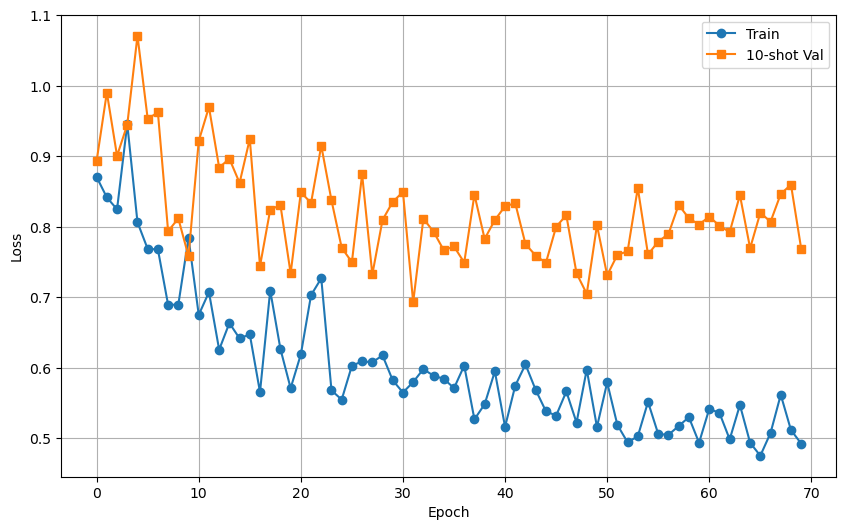

In [19]:
import matplotlib.pyplot as plt

# epochs = list(range(len(history['train_loss'])))

plt.figure(figsize=(10, 6))
plt.plot(her2_maml_model_results_df['epoch'], her2_maml_model_results_df['meta_val_loss'], label='Train', marker='o')
plt.plot(her2_maml_model_results_df['epoch'], her2_maml_model_results_df['few_shot_val_loss'], label='10-shot Val', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.savefig('/cellar/users/atc009/DRPT-MAML/new_MAML_model/results/fold_htonly_HER2+_fewshot/expronly_correctFewShotSampler_inner0.0005_outer0.0005_batch32.png')
plt.show()

In [27]:
# Extract predictions to plot KM survival curves
her2_maml_model_results_npz = np.load('results/fold_htonly_HER2+_fewshot/results.npz')
results_best_epoch = 'epoch_' + str(her2_maml_model_results_npz['best_epoch'])
# print(her2_maml_model_results_npz.files)

# Get best epoch (from results.npz)
prediction_folder = os.path.join(os.getcwd(), 'results/fold_htonly_HER2+_fewshot/predictions')

trial_times = []
trial_events = []
trial_risk_scores = []

for pred_file in os.listdir(os.path.join(prediction_folder, results_best_epoch)):
    if pred_file != 'zero_shot_predictions.npz':
        pred_file_path = os.path.join(prediction_folder, results_best_epoch, pred_file)
        few_shot_pred = np.load(pred_file_path)
        trial_times.append(few_shot_pred['true_times'])
        trial_events.append(few_shot_pred['true_events'])
        trial_risk_scores.append(few_shot_pred['predictions'])


In [28]:
from lifelines.statistics import logrank_test

best_score = None
best_index = None

for i in range(10):
    risk = trial_risk_scores[i]
    time = trial_times[i]
    event = trial_events[i]
    # Median split
    group = np.where(risk >= np.median(risk), 'High', 'Low')
    # Split groups
    ix_high = group == 'High'
    ix_low = group == 'Low'
    # Log-rank test for separation
    result = logrank_test(time[ix_high], time[ix_low], event[ix_high], event[ix_low])
    # Select trial with smallest p-value (best separation)
    if (best_score is None) or (result.p_value < best_score):
        best_score = result.p_value
        best_index = i


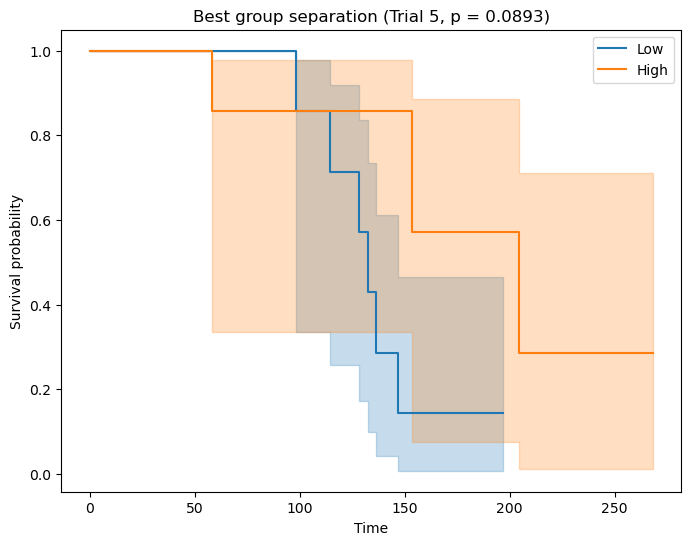

In [29]:
from lifelines import KaplanMeierFitter

# Extract best trial data
risk = trial_risk_scores[best_index]
time = trial_times[best_index]
event = trial_events[best_index]
group = np.where(risk >= np.median(risk), 'High', 'Low')
df = pd.DataFrame({'risk_group': group, 'time': time, 'event': event})

kmf = KaplanMeierFitter()
plt.figure(figsize=(8,6))
for grp in ['Low', 'High']:
    ix = df['risk_group'] == grp
    kmf.fit(df.loc[ix, 'time'], df.loc[ix, 'event'], label=grp)
    kmf.plot_survival_function()
plt.title(f'Best group separation (Trial {best_index}, p = {best_score:.3g})')
plt.xlabel('Time')
plt.ylabel('Survival probability')
plt.legend()
plt.show()


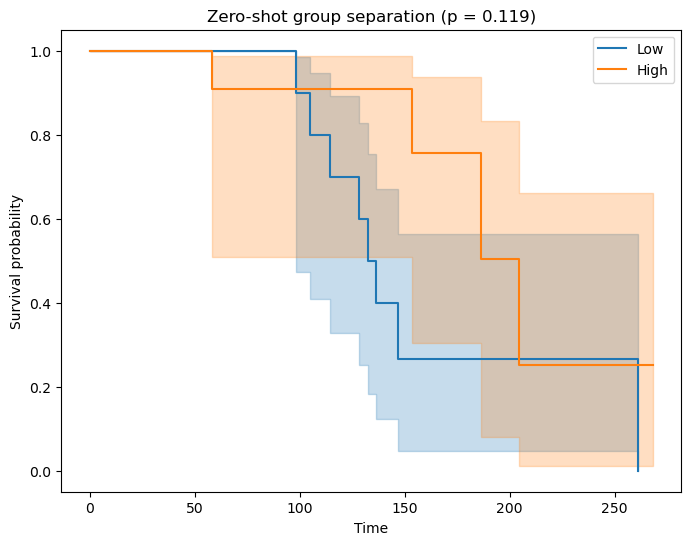

In [31]:
# Extract data to plot KM curves for zero-shot
zero_shot_pred_file_path = os.path.join(prediction_folder, results_best_epoch, 'zero_shot_predictions.npz')
zero_shot_pred = np.load(zero_shot_pred_file_path)

risk = zero_shot_pred['predictions']
time = zero_shot_pred['true_times']
event = zero_shot_pred['true_events']
group = np.where(risk >= np.median(risk), 'High', 'Low')

# Split groups
ix_high = group == 'High'
ix_low = group == 'Low'
# Log-rank test for separation
result = logrank_test(time[ix_high], time[ix_low], event[ix_high], event[ix_low])

df = pd.DataFrame({'risk_group': group, 'time': time, 'event': event})

kmf = KaplanMeierFitter()
plt.figure(figsize=(8,6))
for grp in ['Low', 'High']:
    ix = df['risk_group'] == grp
    kmf.fit(df.loc[ix, 'time'], df.loc[ix, 'event'], label=grp)
    kmf.plot_survival_function()
plt.title(f'Zero-shot group separation (p = {result.p_value:.3g})')
plt.xlabel('Time')
plt.ylabel('Survival probability')
plt.legend()
plt.show()

In [69]:
print(trainer.history['train_loss'])

[0.6930759474635124, 0.6926960075894991, 0.6914804006616274, 0.688598761955897, 0.67878224949042, 0.6687033995985985, 0.6626175617178282, 0.628204012910525, 0.6263866747419039, 0.6142275830109915, 0.5853843751053015, 0.6042497493326664, 0.5947092088560263, 0.5676662810146809, 0.5869418941438198, 0.5610731864968935, 0.5672823414206505, 0.5536134354770184, 0.6136460701624552, 0.5562772875030836, 0.5394503623247147, 0.5435097478330135, 0.5543952311078707, 0.5495458121101061, 0.5660776719450951, 0.5224750153720379, 0.5157560743391514, 0.5276009825368723, 0.5556262855728468, 0.5379755981266499, 0.5040567095081011, 0.5205462016165257, 0.4827472157776356, 0.4914657957851887, 0.486887127161026, 0.46327740636964637, 0.4676690635581811, 0.5036138271292051, 0.47075633083780605, 0.5138140705724558, 0.46881381546457607, 0.4673200423518817, 0.4493679689864318, 0.43852011921505135, 0.4374002180993557, 0.4295222759246826, 0.4557736509790023, 0.42933927041788894, 0.4606308688720067, 0.41590595804154873

In [70]:
print(trainer.history['val_loss'])

[0.6929479241371155, 0.6924884915351868, 0.6907893419265747, 0.6891729831695557, 0.6733640432357788, 0.673725962638855, 0.686387836933136, 0.645291268825531, 0.6163522601127625, 0.636457085609436, 0.6723452806472778, 0.6582890152931213, 0.6680487394332886, 0.614163339138031, 0.699897825717926, 0.6546041965484619, 0.6528639793395996, 0.6650270819664001, 0.6680280566215515, 0.5931167602539062, 0.6623043417930603, 0.5664486289024353, 0.5893779397010803, 0.522784411907196, 0.6738683581352234, 0.6335930824279785, 0.5889028906822205, 0.6600488424301147, 0.6603625416755676, 0.6171273589134216, 0.6124643087387085, 0.6585108041763306, 0.6156124472618103, 0.6761100888252258, 0.675704836845398, 0.6608251333236694, 0.7962411642074585, 0.7604517936706543, 0.5773654580116272, 0.7169818878173828, 0.7471998929977417, 0.8074812889099121, 0.6553801894187927, 0.7431104779243469, 0.6612097024917603, 0.676665723323822, 0.7071774005889893, 0.7688052654266357, 0.8044002056121826, 0.7995935082435608]


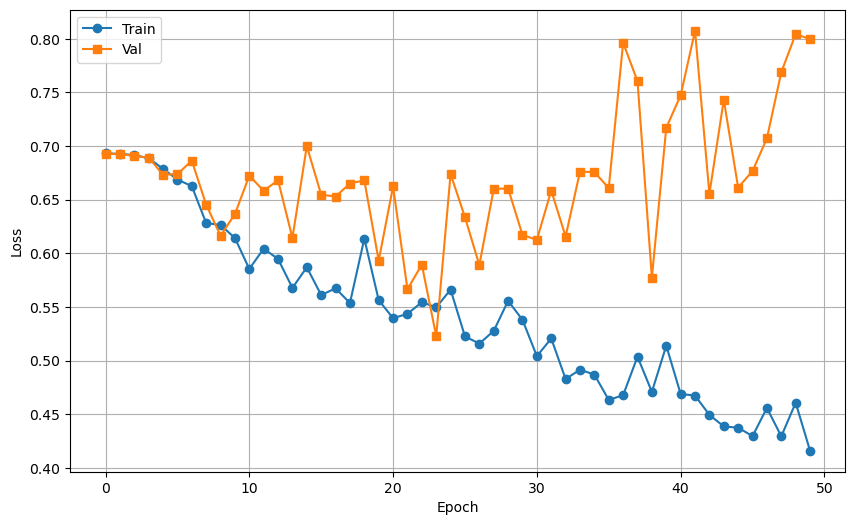

In [71]:
import matplotlib.pyplot as plt
history = trainer.history

epochs = list(range(len(history['train_loss'])))

plt.figure(figsize=(10, 6))
plt.plot(epochs, history['train_loss'], label='Train', marker='o')
plt.plot(epochs, history['val_loss'], label='Val', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.savefig('/cellar/users/atc009/DRPT-MAML/new_MAML_model/results/fold_htonly/expronly_lr0.0001_zero_shot.png')
plt.show()

## Read out results

In [120]:
val_performance_df = pd.read_pickle('results/val_performance_ipynb.pkl')
val_performance_df

{'epochs': [0, 10, 20, 30, 40],
 'harrell': [0.514344262295082,
  0.5286885245901639,
  0.5491803278688525,
  0.5399590163934426,
  0.5532786885245902],
 'cox_loss': [0.6934306025505066,
  0.735906720161438,
  0.9910679459571838,
  1.1181386709213257,
  1.321466326713562]}

In [121]:
val_performance_htonly_df = pd.read_pickle('results/val_performance_htonly.pkl')
val_performance_htonly_df

{'epochs': [0, 10, 20, 30, 40],
 'harrell': [0.5135613207547169,
  0.6188089622641509,
  0.6347287735849056,
  0.6049528301886793,
  0.6049528301886793],
 'cox_loss': [0.6931242346763611,
  0.6826643347740173,
  0.6841742396354675,
  0.8145116567611694,
  0.8281885981559753]}

In [99]:
val_performance_ht_hyperparam_df = pd.read_pickle('results/val_performance_inner0.0005_hidden128_htonly.pkl')
val_performance_ht_hyperparam_df

{'epochs': [0, 10, 20, 30, 40],
 'harrell': [0.5598466981132075,
  0.6423938679245284,
  0.6164504716981132,
  0.5946344339622641,
  0.5757665094339622],
 'cox_loss': [0.6930153369903564,
  0.6615303158760071,
  0.9028789401054382,
  1.0557507276535034,
  1.1371285915374756]}

In [8]:
val_performance_ht_hidden64_df = pd.read_pickle('results/val_performance_inner0.0005_hidden64_htonly.pkl')
val_performance_ht_hidden64_df

# TODO: Train on just expression 
# NOTE: Plot validation loss over epochs (and support/query loss)

{'epochs': [0, 10, 20, 30, 40],
 'harrell': [0.5533423362592843,
  0.5871033085752869,
  0.6147873058744092,
  0.6262660364618501,
  0.612424037812289],
 'cox_loss': [0.6928856372833252,
  0.6706522107124329,
  0.5772144198417664,
  0.7100710272789001,
  0.759192943572998]}

In [146]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"total params: {total_params:,}, trainable params: {trainable_params:,}")

total params: 3,351, trainable params: 3,351


In [147]:
patient2ind_df

,Unnamed: 0,patient_id
0,0,0
1,1,2
2,2,10
3,3,28
4,4,36
...,...,...
1146,1146,4904
1147,1147,3355
1148,1148,506
1149,1149,5238


In [148]:
patient2ind_dict = {str(patient): idx for idx, patient in patient2ind_df.itertuples(False)}

In [183]:
drug_response_df = pd.read_csv(drug_response_file, index_col=0)
patient_id = str(drug_response_df.iloc[2].iloc[0])
patient_id

'10'

In [184]:
patient_ind = patient2ind_dict.get(patient_id, 0)

In [185]:
patient_ind

2